# 周报：2026-11-09 到 2026-11-15（第 1 到第 10 轮）
**视频功能记忆（部件级，记忆方向）** · 写给项目负责人 · 2026-11-16 生成

# 先读这里：用大白话讲这一周

> 这一节写给"没有跟着每一轮讨论"的读者。它只讲大局：我们想回答什么问题、这一周做了什么、为什么这么做、结果怎样、下一步为什么这么选。后面的各节是细节和证据，这一节里的每个数字在后面都能找到出处。

## 1. 我们想回答什么问题

**一个例子。** 你拿着手机（或戴着眼镜）在家里走一圈，录一段视频。过了几天，你问："床头柜最上面那个抽屉怎么打开？"系统要在录下的画面里，指出你该用手碰的那个小部件：抽屉的拉手。它还可以告诉你往哪个方向拉。

**我们要做的是一个"记忆"。** 视频只录一次，存成一份记忆；之后可以问很多次，每次都很快地找到答案，不用把整段视频重新看一遍。

**我们的核心想法（"功能记忆"）。** 一般的记忆按"画面里看起来有什么"来存，比如"这里有床头柜"。我们的想法是按"能对什么做什么"来存，比如"这里有一个可以拉的拉手、一个可以转的旋钮"。我们想知道：这样存，是不是更容易找到要操作的那个部件。

## 2. 先认识几个词

| 词 | 用大白话说 |
| --- | --- |
| 关键帧 | 从视频里挑出来的几十张画面，记忆就存在这些画面上（每个房间 40 张） |
| 部件图（affordance map） | 在画面上标出哪些小部件能操作：拉手、旋钮、开关、插座等 |
| 检索 | 来了一个问题，从几十张画面里挑出最相关的几张（我们挑 3 张） |
| 视觉语言模型 | 能看图回答问题的 AI 模型。我们用开源的 Qwen3-VL，有 4B 和 8B 两个大小（8B 更大） |
| 编号框 | 在图上把候选部件框起来、编上号，让模型直接说"选 3 号" |
| ORACLE（标注） | 用人工标好的部件图代替模型预测。它回答的是"如果部件图完美，最好能做到哪"，是上限，不是方法的真实水平 |
| 对照 | 只拿掉一个因素，看结果变了多少，用来判断功劳到底归谁 |
| 事先写定的规则 | 每个实验跑之前，就写好"怎样算成功"。这样不能看了结果再找说法 |
| 关口（G1、G2） | 事先定好的检查点，过了才往下走。G1：理想条件下这个想法行不行（已过）。G2：用现成工具时主张还站不站得住、要不要训练模型、投哪个会议（还没到） |
| SAM 3 | Meta 公司公开的分割模型：给它一个词（比如 handle），它就在图里把对应的东西框出来 |
| 端到端 | 从问题一路走到最后选出部件，看最后答对没有；不只看中间挑画面那一步 |
| 掌舵代理、审稿代理 | 掌舵代理是帮你推进项目、写这份周报的 AI 助手；审稿代理是只读文件、专门挑毛病的独立 AI 审稿人 |
| 第 N 轮 | 每次向你汇报结果、请你做决定的一轮讨论；这一周从第 1 轮到第 10 轮 |

## 3. 这一周的研究路线（按时间讲）

**第一步：先在理想条件下看这个想法行不行（阶段 1，11 月 12 日）。** 在 30 个真实房间、390 个问题上，用标注的部件图建记忆，看能不能挑对画面。结果：第一张就挑对的比例，按功能存是 66%，只按整张画面是 46%，存同样多的普通分割区域（不管能不能操作）是 47%。所以这个想法在理想条件下成立，关口 G1 通过。补充检查发现，大约一半的好处来自一个很简单的信息："这张画面上有没有可操作的部件"。

**第二步：和"传统做法"比（第 7 轮，你的要求）。** 传统做法是让视觉语言模型直接看原视频（40 帧）自己找部件。结果（用的是标注的部件图，是上限）：用我们的记忆，模型选对部件的比例是 53%，直接看原视频只有 28%。读取时我们的记忆还快 4 到 5 倍（只算读取时的模型调用，不含建记忆的时间），看的图少十几倍。看起来很好。

**第三步：追问这 25 个百分点到底是谁的功劳（第 9 轮）。** 我们的做法其实给了模型两样东西：一是记忆挑出的画面，二是画面上的部件编号框。审稿代理问：功劳是哪一样的？于是加了一个对照 c4：给模型同样的部件编号框，但画面不用记忆挑，只按普通的语义相似度挑。结果 c4 也有 48%，只比记忆少 4 到 7 个百分点（两边都用标注的部件图，是上限）。4B 和 8B 两个模型都一样。**结论：这 25 个百分点几乎都是"部件编号框"的功劳，记忆挑画面只贡献了一小部分。** 另外，按"动作类型"（拉、转、按）来检索也没有用：即使直接告诉它真实的动作类型，也只多 3.8 个百分点（标注的部件图，上限）。

**第四步：调研发现，有两件事别人已经做了（第 9 到 10 轮）。** 一是"从视频建部件图"，已有 FunGraph、Functional-SLAM 等工作。二是"给模型看编号框让它选"，已有 Set-of-Mark、AffordBot 等做法。所以"给模型看编号框"不能当作我们的新贡献；"新的部件图构建方法"算不算贡献，是一个推迟的决定（账本 DF-4），等 SAM 3 的结果出来再定。

**第五步：重新想记忆什么时候才有用（第 10 轮评估）。** 在一个房间里，按普通语义挑画面已经够用了，记忆没什么用武之地。记忆真正该起作用的，是"难找"的时候：录得很长、有很多相似的部件（比如一排一模一样的抽屉）。你采纳了这个新主张。

**第六步：第一次检验新主张，没过（阶段 2b）。** 做法是把多个房间的画面混在一起，故意让检索变难，看功能记忆的优势会不会变大。结果（标注的部件图，上限）：功能记忆一直比普通语义多挑对 12 到 18 个百分点的画面，但这个差距不随难度变大。按事先写定的规则，判为"检索这一步不支持新主张"。

**第七步：你选了两件并行的事（现在）。** 一是用现成工具 SAM 3 建部件图，看不用人工标注时还剩多少（示例图的 6 张关键帧里，SAM 3 的框几乎都落在部件上）。二是在混合之后让模型最后选部件，看端到端的结果。

In [1]:
# the research path of the week, one box per step of the section above (done / failed / running)
import textwrap

import matplotlib.pyplot as plt
from IPython.display import display
from matplotlib.patches import FancyBboxPatch

STEPS = [("1 Phase 1: idea works with annotated maps (66% vs 46%)", "done"),
         ("2 vs raw-video VLM: 53% vs 28%", "done"),
         ("3 Control c4: the gain is the part boxes (48% vs 53%)", "done"),
         ("4 Survey: map building and numbered marks already exist", "done"),
         ("5 New claim: memory helps when retrieval is hard", "done"),
         ("6 Phase 2b: gap steady (12\u201318 pts), does not grow", "failed"),
         ("7 Now: SAM 3 maps + end-to-end pooled test → gate G2", "running")]
STATUS_STYLE = {"done": ("#d7f0d2", "#2e7d32"), "failed": ("#f9d6d5", "#c0392b"), "running": ("#d5e6fb", "#1f5fae")}
WIDTH, GAP, HEIGHT = 2.35, 0.45, 1.85
fig, axis = plt.subplots(figsize=(19, 3.0))
for i, (label, status) in enumerate(STEPS):
    x = i * (WIDTH + GAP)
    fill, edge = STATUS_STYLE[status]
    axis.add_patch(FancyBboxPatch((x, 0), WIDTH, HEIGHT, boxstyle="round,pad=0.05", fc=fill, ec=edge, lw=2.2))
    axis.text(x + WIDTH / 2, HEIGHT - 0.15, status, ha="center", va="top", fontsize=12, weight="bold", color=edge)
    axis.text(x + WIDTH / 2, HEIGHT / 2 - 0.12, textwrap.fill(label, 17), ha="center", va="center", fontsize=12.5, color="#0b0b0b",
              linespacing=1.25)
    if i < len(STEPS) - 1:
        axis.annotate("", xy=(x + WIDTH + GAP - 0.04, HEIGHT / 2), xytext=(x + WIDTH + 0.04, HEIGHT / 2),
                      arrowprops={"arrowstyle": "-|>", "color": "#52514e", "lw": 1.8})
axis.set_xlim(-0.15, len(STEPS) * (WIDTH + GAP) - GAP + 0.15)
axis.set_ylim(-0.15, HEIGHT + 0.15)
axis.axis("off")
fig.tight_layout()
display(fig)
plt.close(fig)

<Figure size 1900x300 with 1 Axes>

## 4. 现在站在哪里

- **最可靠的发现：** 给模型看部件编号框，它找对要操作的部件的比例从约 28% 翻到约 50%。这是"部件图"的价值，不是"记忆检索"的价值。目前这个结果用的是标注的部件图，所以是上限。
- **两个最大的未知：**
  1. 用现成工具建的部件图够不够好？SAM 3 正在跑，示例图看起来很好。
  2. 在难找的时候，记忆能不能帮模型最后选对部件？端到端测试正在排队。
- **另外两条线：**
  - B（问"我做过什么"）暂停了，因为只靠手腕跟踪找不出"拿起、放下"的时刻。
  - C（告诉你怎么动）：第一次试跑发现模型的答题格式不对，改好后已重新排队试跑；全部场景还没开始跑。

## 5. 下一步为什么这么选

- **为什么先做 SAM 3 的检查：** 到现在为止，所有好结果都用的是人工标注的部件图。真正的系统没有标注，必须自己建图。
  - 如果现成工具就能建出好的部件图，系统就可以用"现成工具 + 记忆 + 模型"搭起来。那时论文的价值就要看记忆在"难找"时有没有用。
  - 如果现成工具不行，"把部件图建好"本身可能成为贡献。它算不算贡献，本来就是推迟到这一步再定的（账本 DF-4）。
- **为什么还要做端到端的混合测试：** 检索这一步的差距虽然不变大，但模型最后是从挑出的 3 张画面里选部件。房间混得越多，普通语义挑出的 3 张里"一张对的都没有"的情况就越多，这时给再好的编号框也救不回来。所以最后选对部件的差距，有可能随难度变大。这个测试是在第一步没过之后才加的，解读时要更谨慎。
- **两个结果出来以后：**
  - 如果它们支持主张：下一步是阶段 3，去现成的公开基准上做正式的测试（下载要你批）。
  - 如果都不支持：到关口 G2，由你在三条路里选：
    1. 改成做"新的部件图构建方法"：要训练模型。
    2. 换投稿方向，例如 WACV 的应用方向。
    3. 停下来重新想。

## 6. 掌舵代理的看法（一句话）

这一周的结论比一周前更清楚，也更保守：**部件图是真正起作用的东西；"按功能组织的记忆"能不能成为论文的核心，取决于正在跑的两个检查。** 下周最要紧的是拿到这两个结果，而不是再加新的标注对照。

---

**下面是细节。**

# 细节和证据

下面第 0 到第 9 节是各项的细节和证据，节号自成一套；下文说的"第 x 节"都指这一套。

**配套文档：** [章程](../helm/CHARTER.md) · [账本](../helm/LEDGER.md)（每轮的问题和你的原话）· [审稿台账](../helm/REVIEW.md) · [第 10 轮评估](../helm/assessments/2026-11-13.md) · [讨论稿](../docs/mem/mem分支_问题定义与讨论稿_2026-11-10.md) §11–§26 · [阶段 1 结果 notebook](../notebooks/mem/phase1_results.ipynb)

**这份 notebook 只报告，不替你做决定。** 开头的"先读这里"由掌舵代理撰写，原样收入；要你决定的事集中在第 0 节末尾和第 7 节。写这份周报的代理自己的推断，都标为"推断"。

**读数的约定**
- **百分比：** 除非另说，都是 SceneFun3D 验证集（split 0）30 个场景里 390 个"可回答"任务中的比例。"可回答"指任务要找的部件在我们挑的 40 张关键帧里至少有一张看得到；445 个任务里有 390 个。一个任务的例子："Open the top drawer of the cabinet"。
- **个百分点（点）：** 两个比例之差。例如 54.4% 减 47.7% 是 +6.7 个百分点。
- **方括号 [a, b]：** 按场景重抽样得到的 95% 置信区间。直观地说：换一批同类的场景，结果大概率落在这个范围里。**区间下沿**就是 a。
- **ORACLE（上限）：** 用数据集的标注代替还没做出来的部件图（affordance map，即"画面上哪里可以操作、用什么动作"）。这类数字说明"如果部件图是对的，能做到多少"，不说明方法现在能做到多少。表格里有一列"部件图"注明。
- **出处：** 数字后面的 §x.y 是讨论稿的节号。结果文件都在服务器的 `runs/` 下，不进 git。附录 A 列出每个关键数字取自哪个文件，并在运行时逐个核对。
- **模型：** 4B、8B 指视觉语言模型 Qwen3-VL-4B 和 Qwen3-VL-8B；都是现成的公开模型，没有训练。图里的标签用英文。

<sub>重新运行：在仓库根目录执行 `python notebooks/builders/build_report_2026_11_16_weekly.py report/2026-11-16_weekly_summary.ipynb`，再执行 `jupyter nbconvert --to notebook --execute --inplace report/2026-11-16_weekly_summary.ipynb`。只用 CPU，约一分钟；需要服务器上 `runs/` 里的结果文件。</sub>

In [2]:
import contextlib
import io
import json
import os
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display

warnings.filterwarnings("ignore")
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "affordance3d").is_dir())
_saved_fd, _null = os.dup(1), os.open(os.devnull, os.O_WRONLY)
os.dup2(_null, 1)  # silence Open3D's import banner (printed from C++) if an import below pulls it in
try:
    with contextlib.redirect_stdout(io.StringIO()):
        sys.path.insert(0, str(ROOT))
        from report import pipeline_flowchart as FC  # switches matplotlib to Agg; switched back below
        from report import mem_phase1_helpers as R
finally:
    os.dup2(_saved_fd, 1)
import matplotlib.pyplot as plt
from matplotlib_inline.backend_inline import set_matplotlib_formats

plt.switch_backend("module://matplotlib_inline.backend_inline")
set_matplotlib_formats("png")
plt.rcParams.update({"figure.dpi": 100})
pd.set_option("display.max_colwidth", 200)
pd.set_option("display.max_rows", 200)
RUNS = ROOT / "runs"
FILES = {  # short name -> result file under runs/ (written by the scripts named in each section)
    "phase1": "mem_phase1/summary.json", "diag": "mem_phase1/diagnostics.json", "c4b": "mem_phase1/controls_summary.json",
    "c8b": "mem_phase1/controls_8b_summary.json", "by_action": "mem_phase1/controls_by_action.json",
    "a": "mem_phase1/control_a.json", "ceiling": "mem_phase1/frame_ceiling.json", "errors": "mem_phase1/map_errors.json",
    "errors_centre": "mem_phase1/map_errors_centre.json", "key": "mem_phase1/action_key.json",
    "pooled": "mem_phase1/pooled_retrieval.json", "b0": "hdepic/b0_events.json", "b0_swapped": "hdepic/b0_events_swapped.json",
    "b1": "hdepic/b1_hand_events.json", "c0": "mem_c0/summary.json", "c1_4b": "mem_c1/preview/4b_summary.json",
    "c1_8b": "mem_c1/preview/8b_summary.json"}
missing = [rel for rel in FILES.values() if not (RUNS / rel).is_file()]
if missing:
    raise FileNotFoundError(f"result files missing under runs/: {missing}")
D = {name: json.loads((RUNS / rel).read_text()) for name, rel in FILES.items()}


def get(name, *path):
    value = D[name]
    for key in path:
        value = value[key]
    return value


def rate(d):  # '66.2% [60.0, 73.3]'
    return f"{100 * d['rate']:.1f}% [{100 * d['low']:.1f}, {100 * d['high']:.1f}]"


def diff(d):  # '+18.8 [+12.9, +24.9]'
    return f"{100 * d['rate']:+.1f} [{100 * d['low']:+.1f}, {100 * d['high']:+.1f}]".replace("-", "−")


def show(fig):
    display(fig)
    plt.close(fig)


INK, MUTED, GRID = R.INK, R.MUTED, R.GRID
BOX, NOBOX, GENERIC, MEMORY = R.POLICY_COLOUR[R.A.P4], "#e34948", R.POLICY_COLOUR[R.A.P3], "#1baf7a"
print(f"{len(FILES)} result files read; phase 1: {get('phase1', 'scenes')} scenes, {get('phase1', 'tasks')} of "
      f"{get('phase1', 'tasks_all')} tasks answerable")

17 result files read; phase 1: 30 scenes, 390 of 445 tasks answerable


In [3]:
# small figures of this report; the phase-1 and control-c figures come from report/mem_phase1_helpers.py


def headline_figure(c4b, c8b):
    arms = [("c3", "c3: raw video, 40 even frames;\nVLM picks a frame, draws a box"),
            ("c1s", "c1': 3 keyframes chosen by meaning;\nVLM picks one, draws a box"),
            ("c2s", "c2': the memory's 3 keyframes;\nVLM picks one, draws a box"),
            ("c4", "c4: annotated part boxes on 3 keyframes\nchosen by meaning; VLM picks a number"),
            ("p4n", "P4: annotated part boxes on the memory's\n3 keyframes; VLM picks a number")]
    fig, axis = plt.subplots(figsize=(11.5, 4.9))
    for row, (arm, _) in enumerate(arms):
        colour = BOX if arm in ("c4", "p4n") else NOBOX
        for offset, summary, model, alpha in ((-0.2, c4b, "4B", 0.5), (0.2, c8b, "8B", 1.0)):
            d = summary["arms"][arm]["right_part"]
            axis.barh(row + offset, 100 * d["rate"], height=0.36, color=colour, alpha=alpha)
            axis.plot([100 * d["low"], 100 * d["high"]], [row + offset] * 2, color=INK, lw=1.1)
            axis.text(100 * d["high"] + 1.0, row + offset, f"{100 * d['rate']:.1f}% ({model})", va="center", fontsize=8.5, color=INK)
    axis.set_yticks(range(len(arms)), [label for _, label in arms], fontsize=9, color=INK)
    axis.invert_yaxis()
    axis.axhline(2.5, color=MUTED, lw=0.8, ls="--")
    axis.set_xlim(0, 80)
    axis.set_title("Share of tasks where the chosen box lies on the target part (%); light = 4B, dark = 8B; line = 95% interval\n"
                   "red: no part boxes, the VLM draws its own box; blue (below the dashed line): numbered annotated part boxes (ORACLE)",
                   fontsize=10, loc="left", color=INK)
    R._clean(axis)
    fig.tight_layout(rect=(0, 0.04, 1, 1))
    R._oracle_note(fig, "390 tasks, 30 SceneFun3D scenes. c4 and P4 use annotated part maps (ORACLE, upper bounds); c2' and P4 "
                        "take keyframes picked by the memory, whose keyframe flag also comes from the annotations.")
    return fig


def timeline_figure():
    days = ["11-09\nMon", "11-10\nTue", "11-11\nWed", "11-12\nThu", "11-13\nFri", "11-14\nSat", "11-15\nSun", "11-16\nMon"]
    commits = [5, 9, 7, 7, 24, 24, 2, 1]
    events = ["dataset report;\nlocal prototype", "rounds 1-2;\nS1 steps 1-5;\nrepository split", "rounds 3-4;\n15 pipeline\nblocks",
              "rounds 5-6;\nphase-1 spec;\nhelm charter", "phase 1;\nrounds 7-9;\ncontrols c, a, b,\nd, c+; R7-B",
              "(work of 11-13\nafter midnight)\nc4, 8B; B-0, B-1,\nC-0; round 10; 2b", "answer 'c+a';\n2b end-to-end\nplanned",
              "queue 'b';\ngate seen,\n'a' (after\nthe week)"]
    fig, axis = plt.subplots(figsize=(12, 4.3))
    colours = [MUTED if i in (0, 7) else BOX for i in range(len(days))]
    axis.bar(range(len(days)), commits, color=colours, width=0.6)
    for x, (n, text) in enumerate(zip(commits, events)):
        axis.text(x, n + 0.8, f"{n}", ha="center", va="bottom", fontsize=9, color=INK, weight="bold")
        axis.text(x, n + 3.2, text, ha="center", va="bottom", fontsize=7.8, color=MUTED, linespacing=1.15)
    axis.set_xticks(range(len(days)), days, fontsize=9, color=INK)
    axis.set_ylim(0, 44)
    axis.set_ylabel("commits", fontsize=9, color=MUTED)
    axis.set_title("Commits per day (commit timestamps) and what happened; rounds by the ledger's dates", fontsize=10, loc="left",
                   color=INK)
    R._clean(axis, grid="y")
    fig.tight_layout()
    return fig


def bars_and_differences(rows, keys, labels, colours, diff_rows, diff_keys, diff_labels, diff_colours, left_title, right_title,
                         note, rule_at=None, rule_text=""):
    height = 0.62 * max(len(keys), len(diff_keys)) + 1.6
    fig, (left, right) = plt.subplots(1, 2, figsize=(13.5, height), gridspec_kw={"width_ratios": [1.1, 1]})
    R._rate_bars(left, rows, keys, labels, colours)
    left.set_title(left_title, fontsize=10, loc="left", color=INK)
    R._difference_dots(right, diff_rows, diff_keys, diff_labels, diff_colours)
    right.set_title(right_title, fontsize=10, loc="left", color=INK)
    if rule_at is not None:
        right.axvline(rule_at, color=MUTED, lw=1, ls="--")
        right.text(rule_at - 0.3, len(diff_keys) - 0.55, rule_text, fontsize=8, color=MUTED, ha="right", va="bottom")
    fig.tight_layout(rect=(0, 0.04, 1, 1))
    R._oracle_note(fig, note)
    return fig


def map_error_figure(errors, centre):
    keeps, alarms = ["1", "0.75", "0.5", "0.25"], ["0", "0.5", "1", "2"]
    fig, axes = plt.subplots(2, 2, figsize=(10, 7.8))
    for row, (data, rule) in enumerate(((errors, "false alarm = generic region with IoU < 0.5 to every part (pre-set rule)"),
                                        (centre, "stricter re-run: no generic region whose centre lies on a part"))):
        for col, (order, title) in enumerate((("random", "parts dropped at random"), ("smallest_first", "smallest parts dropped first"))):
            axis = axes[row, col]
            grid = np.array([[100 * data["grid"][order][k][a]["rate"] for a in alarms] for k in keeps])
            axis.imshow(grid, cmap="Blues", vmin=40, vmax=70)
            for i, k in enumerate(keeps):
                for j, a in enumerate(alarms):
                    better = data["grid"][order][k][a]["against_p3"]["verdict"] == "clearly better"
                    axis.text(j, i, f"{grid[i, j]:.1f}" + ("" if better else "\n= P3"), ha="center", va="center", fontsize=9,
                              color="white" if grid[i, j] > 60 else INK, weight="normal" if better else "bold")
            axis.set_xticks(range(4), ["0", "0.5x", "1x", "2x asked"], fontsize=9)
            axis.set_yticks(range(4), ["100%", "75%", "50%", "25%"], fontsize=9)
            axis.set_xlabel("false alarms, as a multiple of the true parts", fontsize=8.5, color=MUTED)
            axis.set_ylabel("share of true parts kept", fontsize=8.5, color=MUTED)
            axis.set_title(f"{title}\n{rule}", fontsize=8.8, loc="left", color=INK)
    fig.suptitle("First keyframe right (%) when the annotated part map is damaged; '= P3' marks cells not clearly better than generic "
                 f"regions (P3 {100 * errors['p3']:.1f}%, whole keyframes {100 * errors['p0']:.1f}%)", fontsize=10, x=0.01, ha="left")
    fig.tight_layout(rect=(0, 0.04, 1, 0.95))
    R._oracle_note(fig, "Perturbed annotations, retrieval only, no VLM. The 2x column held 1.46x (1.39x in the stricter re-run) on average.")
    return fig


def pooled_figure(pooled):
    sizes = pooled["pool_sizes"]
    per = pooled["per_size"]
    fig, (left, right) = plt.subplots(1, 2, figsize=(13.5, 4.6))
    for arm, colour in (("semantic", R.POLICY_COLOUR[R.A.P0]), ("function index", BOX), ("function index + action key", "#eda100")):
        rows = [per[str(k)][arm]["top3"] for k in sizes]
        left.fill_between(sizes, [100 * r["low"] for r in rows], [100 * r["high"] for r in rows], color=colour, alpha=0.12, lw=0)
        left.plot(sizes, [100 * r["rate"] for r in rows], "-o", color=colour, lw=2, ms=6, mec="white", label=arm,
                  ls="--" if "key" in arm else "-")
    left.set_ylabel("right keyframe among the top 3 (%)", fontsize=9, color=MUTED)
    left.legend(frameon=False, fontsize=9)
    left.set_title("Retrieval when K scenes are pooled into one memory", fontsize=10, loc="left", color=INK)
    for offset, key, colour, label in ((-0.06, "function index minus semantic (top3)", BOX, "function index − semantic"),
                                       (0.06, "function index + action key minus function index (top3)", "#eda100",
                                        "action key − function index")):
        rows = [per[str(k)][key] for k in sizes]
        xs = [k * 2 ** offset for k in sizes]
        right.errorbar(xs, [100 * r["rate"] for r in rows], yerr=[[100 * (r["rate"] - r["low"]) for r in rows],
                       [100 * (r["high"] - r["rate"]) for r in rows]], fmt="o", color=colour, capsize=3, label=label)
    reading = pooled["readings"]["function index minus semantic"]["slope_per_doubling"]
    right.axhline(0, color=INK, lw=0.8)
    right.set_ylabel("paired difference, points (95% interval)", fontsize=9, color=MUTED)
    right.set_title(f"Gap per K; slope of the gap: {diff(reading)} points per doubling", fontsize=10, loc="left", color=INK)
    right.legend(frameon=False, fontsize=9, loc="center right")
    for axis in (left, right):
        axis.set_xscale("log", base=2)
        axis.set_xticks(sizes, [str(k) for k in sizes])
        axis.minorticks_off()
        axis.set_xlabel("K: scenes pooled into one memory (the target scene + K-1 others)", fontsize=9, color=MUTED)
        R._clean(axis, grid="y")
    fig.tight_layout(rect=(0, 0.04, 1, 1))
    R._oracle_note(fig, "Annotated part maps (ORACLE) on both sides; retrieval only, no VLM. 390 tasks; 5 draws of the other scenes per K > 1.")
    return fig


def hdepic_figure(b0, b0s, b1):
    fig, (left, right) = plt.subplots(1, 2, figsize=(13.5, 4.6), gridspec_kw={"width_ratios": [1, 1.2]})
    for x, (summary, label, colour) in enumerate(((b0["summary"], "as written", NOBOX), (b0s["summary"], "box axes swapped (post hoc)", BOX))):
        for offset, key, n in ((-0.18, "tied_share", "questions"), (0.18, "reproduced_share", "rule_questions")):
            left.bar(x + offset, 100 * summary[key], width=0.32, color=colour, alpha=1.0 if offset < 0 else 0.55)
            left.text(x + offset, 100 * summary[key] + 1.5, f"{100 * summary[key]:.1f}%", ha="center", fontsize=8.5, color=INK)
        left.text(x, 108, label, ha="center", va="bottom", fontsize=9, color=colour, weight="bold")
    left.axhline(90, color=INK, lw=1, ls="--")
    left.text(-0.55, 91, "bar: 90%", fontsize=8.5, color=INK, ha="left", va="bottom")
    left.set_xticks([-0.18, 0.18, 0.82, 1.18], ["questions\ntied", "answers\nreproduced", "questions\ntied", "answers\nreproduced"],
                    fontsize=8.5)
    left.set_xlim(-0.6, 1.6)
    left.set_ylim(0, 125)
    left.set_title("B-0 (kitchen P02, 242 questions): questions tied to annotated\nevents; rule answers reproduced (of 54)", fontsize=10,
                   loc="left", color=INK)
    R._clean(left, grid="y")
    summary = b1["summary"]
    right.add_patch(plt.Rectangle((50, 60), 50, 40, color=BOX, alpha=0.08, lw=0))
    right.text(52, 97, "pass: precision >= 50% with recall >= 60%", fontsize=8.5, color=BOX, va="top")
    curve = summary["curve"]
    right.plot([100 * curve[k]["precision"] for k in curve], [100 * curve[k]["recall"] for k in curve], "-o", color=MUTED, ms=5)
    offsets = {"0.05": (6, -4), "0.1": (6, -4), "0.15": (8, -12), "0.2": (-46, 3), "0.3": (6, 2)}
    for k in curve:
        right.annotate(f"{k} m/s", (100 * curve[k]["precision"], 100 * curve[k]["recall"]), textcoords="offset points",
                       xytext=offsets.get(k, (6, -3)), fontsize=7.5, color=MUTED)
    right.plot(100 * summary["precision"], 100 * summary["recall"], "o", color=NOBOX, ms=10, label="pre-set operating point (0.15 m/s)")
    shift = summary["control_shift_15s"]
    right.plot(100 * shift["precision"], 100 * shift["recall"], "s", color=INK, ms=7, label="control: detections shifted by 15 s")
    ceiling = 100 * summary["palm_within_30cm_at_0"] * summary["clock_check_palm_to_object"]["n_at_0"] / summary["truths"]
    right.axhline(ceiling, color=INK, lw=0.8, ls=":")
    right.text(99, ceiling + 1, f"about {ceiling:.0f}%: a tracked palm is within 30 cm at the annotated moment", fontsize=8, ha="right")
    right.set_xlim(0, 100)
    right.set_ylim(0, 100)
    right.set_xlabel("precision (%)", fontsize=9, color=MUTED)
    right.set_ylabel("recall (%)", fontsize=9, color=MUTED)
    right.set_title(f"B-1: pick-ups and put-downs from the hand track alone ({summary['truths']:,} annotated)", fontsize=10, loc="left",
                    color=INK)
    right.legend(frameon=False, fontsize=8.5, loc="lower right")
    R._clean(right, grid="both")
    fig.tight_layout(rect=(0, 0.04, 1, 1))
    R._oracle_note(fig, "HD-EPIC kitchen P02, CPU only; annotations used only for scoring. B is paused since round 10.")
    return fig


def c_figure(c0, c1_4b, c1_8b):
    fig, (left, right) = plt.subplots(1, 2, figsize=(13.5, 4.6), gridspec_kw={"width_ratios": [0.8, 1.4]})
    criteria = c0["criteria"]
    rows = [("every target part has a motion", criteria["motions_for_every_part"]["share"], criteria["motions_for_every_part"]["threshold"]),
            ("motion arrow >= 20 px on the keyframe", criteria["arrow_at_least_20px"]["share"], criteria["arrow_at_least_20px"]["threshold"]),
            ("scorer gives the truth 100%", 1.0 if criteria["scorer_gives_truth_100"]["holds"] else 0.0, 1.0)]
    for y, (label, share, bar) in enumerate(rows):
        left.barh(y, 100 * share, height=0.5, color=MEMORY)
        left.plot([100 * bar] * 2, [y - 0.32, y + 0.32], color=INK, lw=2)
        left.text(2, y, f"{100 * share:.1f}%  (bar {100 * bar:.0f}%)", va="center", fontsize=9, color="white")
    left.set_yticks(range(3), [r[0] for r in rows], fontsize=9)
    left.invert_yaxis()
    left.set_xlim(0, 105)
    left.set_title("C-0: action records, 390 tasks (all three bars met)", fontsize=10, loc="left", color=INK)
    R._clean(left)
    fields = [("contact", "contact on\nthe part"), ("label", "affordance\nlabel"), ("type", "motion type"),
              ("line_ok", "direction line\nwithin 20 deg"), ("joint", "joint success\n(all of these)")]
    arms = [(c1_4b, "M", "M (memory), 4B choice", BOX, 0.5), (c1_4b, "M4", "M4 (no memory), 4B choice", GENERIC, 0.5),
            (c1_8b, "M", "M (memory), 8B choice", BOX, 1.0), (c1_8b, "M4", "M4 (no memory), 8B choice", GENERIC, 1.0)]
    width = 0.19
    for i, (summary, arm, label, colour, alpha) in enumerate(arms):
        xs = np.arange(len(fields)) + (i - 1.5) * width
        values = [summary["arms"][arm][f]["rate"] for f, _ in fields]
        right.bar(xs, [100 * v for v in values], width=width, color=colour, alpha=alpha, label=label)
        for x, f in zip(xs, [f for f, _ in fields]):
            d = summary["arms"][arm][f]
            right.plot([x, x], [100 * d["low"], 100 * d["high"]], color=INK, lw=0.9)
    right.set_xticks(range(len(fields)), [label for _, label in fields], fontsize=9)
    right.set_ylim(0, 100)
    right.set_ylabel("share of 380 tasks (%)", fontsize=9, color=MUTED)
    right.legend(frameon=False, fontsize=8, ncol=2, loc="upper right")
    right.set_title("C-1 CPU preview: memory (M) vs the same annotated boxes on frames picked without it (M4)", fontsize=10, loc="left",
                    color=INK)
    R._clean(right, grid="y")
    fig.tight_layout(rect=(0, 0.04, 1, 1))
    R._oracle_note(fig, "M and M4 both take the contact point and label from annotated regions (ORACLE). The preview has no V or G arm "
                        "(they need the GPU) and is not in the draft yet.")
    return fig

## 0. 总览：状态、数字和出处

开头的"先读这里"讲了大局。这一节只把状态和关键数字列在一处，每一条指向后面的细节和讨论稿的节号。

**北极星和贡献类型（章程）：** NeurIPS 2027 主会为主目标；是否先投 ICCV 2027、WACV 的 Applications track 是否加入，都到关口 G2 定。贡献类型是应用：构建一条新的 pipeline，核心不完全在算法创新（你 2026-11-12 的定义）。贡献必须"主要做memory system而不是robotics"（你的原话，2026-11-10），想法本身要立得住、不是插件。
- **方向（你的原话，2026-11-10）：** "我构建的mem system包含的不只是semantic的内容更是每个object possible的action结果……我希望探索这种action的sequence或者human和obj的affordance map能不能辅助用来帮助构建mmeory system，这种变为4d的search效果是否会比传统静态3d搜索好"

**项目现在在哪里**

| 项 | 现在的状态 |
| --- | --- |
| 阶段 | validate（验证）：在小规模上检验主张，还没到写论文的阶段 |
| 已过的关口 | 理解、方向、流程（限阶段 1 的范围）、主张、G1（第 7 轮："通过，按收窄后的含义"） |
| 没到的关口 | G2：主张是否成立、是否训练写入器、投哪个会议；G3："4D"是否留在标题里 |
| 采纳的主张 | 第 10 轮（2026-11-13，你回答"1 同意"）：一次走动视频写成的功能记忆，在检索变难的时候（录得长、相似部件多），比"按语义挑画面 + 同样的部件框"更可靠地找到要操作的部件，而且越难优势越大；在单个房间这种容易的情形，起作用的是部件图本身（评估第 4 节） |
| 这个主张的第一次检验 | 预测 2 的第一步（阶段 2b：把 30 个场景的关键帧混在一起检索）在**检索这一步没有通过**：功能索引一直比语义检索多 12 到 18 个百分点，但这个差不随混入的场景变多而变大（§26，ORACLE） |
| 章程提案 P-4 | 暂缓（你 2026-11-15 的原话："P-4 先不批"）。所以章程的"当前主线"一行仍按第 9 轮的方案乙写着；实际执行按账本里你第 10 轮和 11-15 的回答 |

**本周 5 个发现**（数字的出处见括号；附录 A 逐个核对）
1. **编号部件框最可靠：** 选对部件从约 28%（直接读 40 帧原视频：4B 28.5%、8B 27.7%）到约 50%（P4：4B 53.1%、8B 54.4%）；框来自标注，ORACLE；机制别人做过（第 3.2、3.4 节；§24.5、§24.8；评估第 5 节）。
2. **单个房间里记忆挑画面只多 4 到 7 个百分点：** P4 减 c4，4B +4.4 [−0.9, +9.6]，8B +6.7 [+1.8, +11.5]，按事先的规则都是"接近"；ORACLE（第 3.4 节；§24.8）。
3. **动作方向没有证据，不再当主张：** 动作类型之间 p = 0.16；动作键 +0.8 [−0.9, +2.4]，真值上限 +3.8 [+0.9, +7.5]；ORACLE（第 3.6 节；§24.5、§24.10）。
4. **2b：检索变难时优势没有变大：** 前 3 张里有对的，功能索引减语义从 +13.8 [+8.7, +19.2]（1 个场景）到 +11.8 [+8.3, +15.7]（16 个场景），斜率每翻一倍 −0.7 [−2.2, +0.7]；ORACLE，只看检索（第 3.7 节；§26）。
5. **B 停，C 往前走：** B-1 召回 27.6%、精度 15.5%，没过；C-0 通过；C-1 的 CPU 预览里 M 减 M4 只多 1 到 2 个百分点（ORACLE，预览没记进讨论稿）（第 3.8、3.9 节；§25.4）。

**11-16 和现在在跑什么**（详见第 7 节；截至 2026-11-16 晚上，服务器时间）
- 网络断后队列有 793 个作业；你答"b"：示例图和 C-1 试跑插到前面，2b 端到端仍排在你的作业后面。
- 示例图你看过，定"a，插到前面"：只用 SAM 3、Qwen 的检测不做，流程关口算通过；SAM 3 的全部运行已排在前面并开始写出结果（本 notebook 不读）。
- C-1 4B 试跑因答案格式 V、G、V'、G' 都是 0；改了 V 的提问（D-11，缓存 c1-v2），重新排队（第 3.9 节；§25.5）。

**下一个决定点：** SAM 3 版的 2a 按 §24.9 的读法看预测 1；2b 端到端按 §26.2 的读法看预测 2；两个都不支持时，到 G2 由你在"新的构建方法、换会议、重新想"之间选（评估第 10 节）；P-4 等这两个结果再改写。

**最大的风险**（评估第 7 节）：现成工具建的部件图漏掉小部件；或者检索变难时功能索引仍赢不了"语义挑画面 + 同样的部件图"。第 3.5 节的模拟里，先丢小部件、只剩四分之一时检索上的优势就没了（对标注的扰动，不是真实工具）。

**掌舵代理的看法：** 完整原文照录在细节部分的第 6 节（"Research scope 大局"），并在那里展开；开头"先读这里"的第 6 小节是它的一句话版本。

**一张图看本周最可靠的结果：** 横条是选对部件的比例。上面三组没有部件框（模型自己画框），下面两组给了标注的编号部件框。

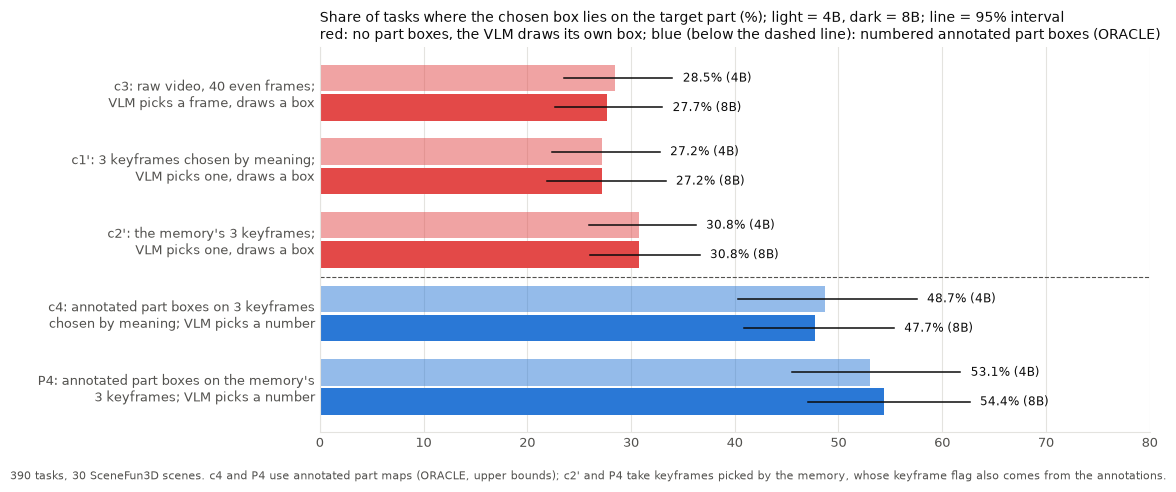

In [4]:
show(headline_figure(D["c4b"], D["c8b"]))

**怎么看：** 有没有部件框，差约 20 到 25 个百分点（上三组对下两组）。有了部件框之后，"记忆挑的画面"（P4）比"按语义挑的画面"（c4）只多几个点。没有部件框时，记忆挑的画面（c2'）比按语义挑的（c1'）也只多几个点。

## 1. 本周时间线

下图是每天的提交数和那天发生的事。**注意日期的口径：** 账本按工作日记录，第 7 到第 10 轮都记在 11-13；但 11-13 晚上的工作一直做到 11-14 凌晨，所以 11-14 的 24 个提交大多属于 11-13 的那几轮。

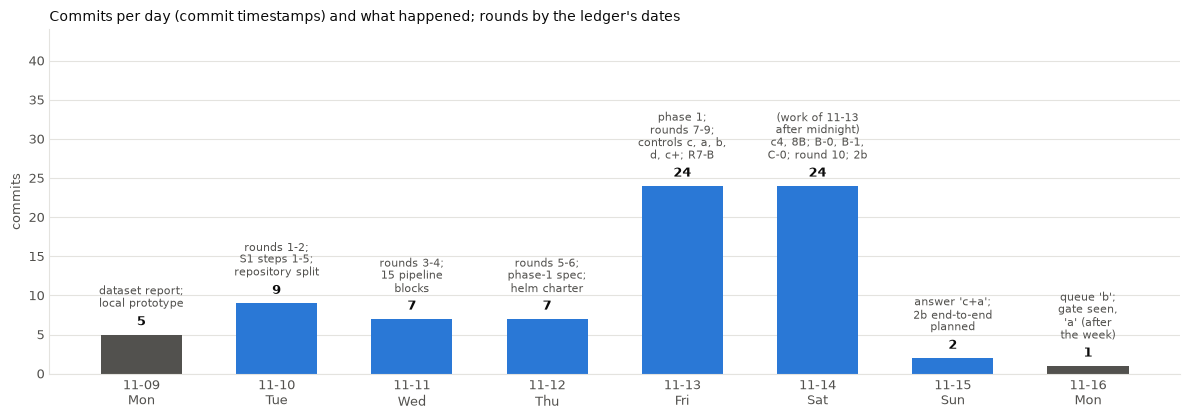

In [5]:
show(timeline_figure())

**按天看**

| 日期 | 做了什么 | 提交数 |
| --- | --- | --- |
| 11-09（周一） | 组会的数据报告（`report/2026-11-09_datasets_report.ipynb`）；本地原型：RGB-D 几何、DINOv2 特征、体素记忆；SceneFun3D 的读取和 E0 对齐检查。这一天记忆方向还没有单独分出来 | 5 |
| 11-10（周二） | 记忆方向开题（讨论稿 §1–§10）；第 1、2 轮；S1 第 1–5 步（ORACLE 版：只用视频、深度和位姿算接触点、表面朝向和站立点）；SMPL-X 人形和短动画；整条 pipeline 的演示 notebook；仓库拆分：VLA 方向移到独立仓库 `affordance-vla`；工作环境迁到实验室的服务器 | 9 |
| 11-11（周三） | 服务器环境；流程细化成 15 个环节（pipeline 工作 notebook）；第 3 轮（记忆带时间、不做稠密重建、存储倾向隐式）；第 4 轮（存储形式定为 L2） | 7 |
| 11-12（周四） | L2 记忆的代码，每个环节一个示例；第 5 轮（研究层面的评估和路线，提案）；第 6 轮（采纳"功能记忆"，以 NeurIPS 为主，批准阶段 1，规格和 G1 规则在跑之前写定）；接入 research-helm（章程、账本、提案 P-1）；阶段 1 的工具 | 7 |
| 11-13（周五） | 阶段 1 跑完并记录（§22）；审稿后的归因检查（§23）和三轮审稿；第 7 轮简报改写成一份白话文档、附流程图；G1 通过；第 8 轮复述你描述的论文；对照 c；R7-B 模拟；动作类型的检验；第二批 a、b、d、c+；第 9 轮简报和你的回答 | 24 |
| 11-14（周六，提交日期） | 账本记在 11-13 的工作：P-3 写进章程；现成工具的桌面核对；B-0、B-1、C-0；c4、c1'、c2'（4B 和 8B）；动作键检查；C-1 的代码和 M4；第 10 轮评估和你的回答；2b 的计划、代码和结果；P-4 | 24 |
| 11-15（周日） | 你对 2b 结果的回答"c+a；P-4 先不批"；§26.2 端到端版本的计划和代码 | 2 |
| 11-16（周一，本周之后） | 服务器网络断了一阵；你对队列位置的回答"b"；两个小作业插到前面并跑完；示例图给你看过，你定"a，插到前面"（只用 SAM 3），SAM 3 的全部运行排到前面；C-1 试跑发现答案格式问题，改了 V 的提问（D-11）并重新排队 | 1（只列到本 notebook 第一版之前的提交） |

**按轮看**（第 1–6 轮在接入 research-helm 之前完成，账本只做索引，没有逐字记下你的回答；这几轮写的是讨论稿记下的决定，有原话的标了引号）

| 轮 | 日期 | 问了什么 | 你的回答（原话，节选） | 之后做了什么 |
| --- | --- | --- | --- | --- |
| 1 | 11-10 | 核心主张、输入、人形的用途、定位、能否自录数据 | 无逐字记录；章程引用的原话："自录的非公开数据难以证明效果，也无法与其他基准对比" | 定位为"部件级 4D 功能记忆"；从视频开始，三维重建只当训练和评测的真值；人形只用于展示；以 H3（交互帮助构建）、H2（事件帮助检索）为主（§11）；设计 v0.2（§12） |
| 2 | 11-10 | 深度、位姿、人形展示、动作词表、顺序 | 无逐字记录 | 单目深度为主、LiDAR 作对比；允许设备位姿；用 SceneFun3D 的 9 类动作；依次推进 S1→S2→S3；逐步向导师汇报（§14） |
| 3 | 11-11 | 对需求的理解、"不做稠密重建"、精度分两档、阶段安排、总览 v2 | 无逐字记录 | 记忆带时间、记录实际发生的动作；不做稠密重建；先"找到并走到跟前"、再"碰到"；存储倾向隐式（§18） |
| 4 | 11-11 | 隐式到哪一档、哪些保持显式、几何量、谁来读记忆、用哪种特征 | 无逐字记录 | 存储形式 L2：每张关键帧的图，加部件 token 和薄的显式索引；接触点等几何在读取时现算（§19）；15 个环节各一个示例 |
| 5 | 11-12 | 确认总览 v2；你要一次研究层面的点评 | "流程基本理解，也大致没有问题"（章程引用）；同时认为作为研究课题还不够 | 评估和路线（提案）：主张"功能记忆"，预测 A（写在哪里）、B（事件）、C（代价），四个阶段、三个关口（§20） |
| 6 | 11-12 | 主张、目标会议、阶段 1、人形 | 无逐字记录 | 采纳"功能记忆"；NeurIPS 为主、ICCV 到 G2 定；批准阶段 1；人形降为补充材料里的演示；阶段 1 的规格和 G1 的判定规则在跑之前写定（§21） |
| 7 | 11-12 到 11-13 | 阶段 1 的结果：G1 是否通过、贡献怎么划分、补哪些对照、用什么真实场景讲 | "通过，按收窄后的含义"；"……最好还是使用传统的vlm模型直接读取原video来完成整体系统的对比"；"都做，但是先做c在做其他"；"我希望优先一和三，二作为补充说明"；另外要求"之后每次阶段性汇报的时候，都给我一个流程图" | G1 过；对照 c 里加了"直接读原视频"一组（D-6）；使用场景以家里的使用指导、无障碍与远程协助为主；以后每次阶段汇报附流程图、决定集中在一份文档 |
| 8 | 11-13 | 复述你在聊天里描述的论文（CA 新构建方法、CB 按功能搜索、CC 更快更准、CD 动作类更强），5 处确认 | "1 对；2 同意；4 参考其他模型的比较，尽量能够横向对齐；5 同意"；""action 的方向"指AC，但是为了能够具有平行比较的能力，希望能够同时做B" | 4 个调研代理（已有的构建方法、对手的设置、B 和 C 的可行性、四项贡献的撞车检查）；章程提案 P-2 |
| 9 | 11-13 | 对照 c 和调研之后：论文重心放在甲、乙、丙哪个；B、C 的头两步；换 8B；补 c4、c1'、c2' | "1 乙；1b 同意你的建议；2 批，并且先做问题 7 和问题 6a；3 批；4 可以；5 批；6a 批，插到队列前面；6b 同意你的建议；7 同意你的建议" | 收回第 8 轮"新构建方法是贡献"那一条，记为 DF-4；P-3 批准并写进章程；SAM 3 许可证"可以，同意许可证，从镜像下载"、GPU"批到 7 小时"；B-0 修补后"1 接受"；c4 接近 P4，按规则停下讨论（"同意你的建议"） |
| 10 | 11-13 | 评估：主张改成"检索变难时"；恢复问题 2 的检查；停的规则；2b；动作方向；B；C-1 的规则 | "1 同意；2 恢复；3 b；4 批；5 b；6 a；7 同意你的建议，a" | 2b 当天写计划、跑完：检索这一步没过；P-4 写好待批 |
| — | 11-15 | 2b 之后怎么走：(a) 测端到端；(b) 接受结果、到 G2；(c) 先只做现成工具的检查 | "c+a；P-4 先不批" | 两件都做；§26.2 的计划写明"这是第一步没过之后才加的检查"；代码写好、排队 |
| — | 11-16 | 网络断后队列里有 793 个作业：两个小作业要不要插到前面 | "b" | 示例图和 C-1 试跑插到前面；2b 端到端不动 |
| — | 11-16 | 看过示例图之后：(a) 只用 SAM 3 全部跑，Qwen 这次不做；(b) 先改 Qwen 的提示词再看；(c) 两个都跑 | "a，插到前面" | 流程关口算通过；只跑 SAM 3（以它为准），Qwen 的检测不做；这项检查的 GPU 作业插到前面 |

## 2. 流程图：现在的流程和第 10 轮的目标

**怎么看这张图**
- **下面两行是今天的流程。** "写入"每段视频做一次，结果就是记忆；"读取"每来一个问题做一次。
- **最上面一行是第 10 轮采纳的目标里要变的东西。** 灰色表示还没做；虚线指向它要替换或改变的那个方框。
- **颜色：** 绿色只用输入算；橙色暂时用标注（ORACLE）；蓝色是没训练的公开模型；灰色还没做。斜线表示这个方框吃的是 ORACLE 方框的输出，所以它的数字也是上限。
- **红框和红标签（Pred1、Pred2、Pred3）：** 第 10 轮主张的三个预测落在流程的哪里。图下面每一行的方括号是这个预测的证据现在到哪一步（照记录写，不是新结果）。灰色"design"一行是不声称的机制。

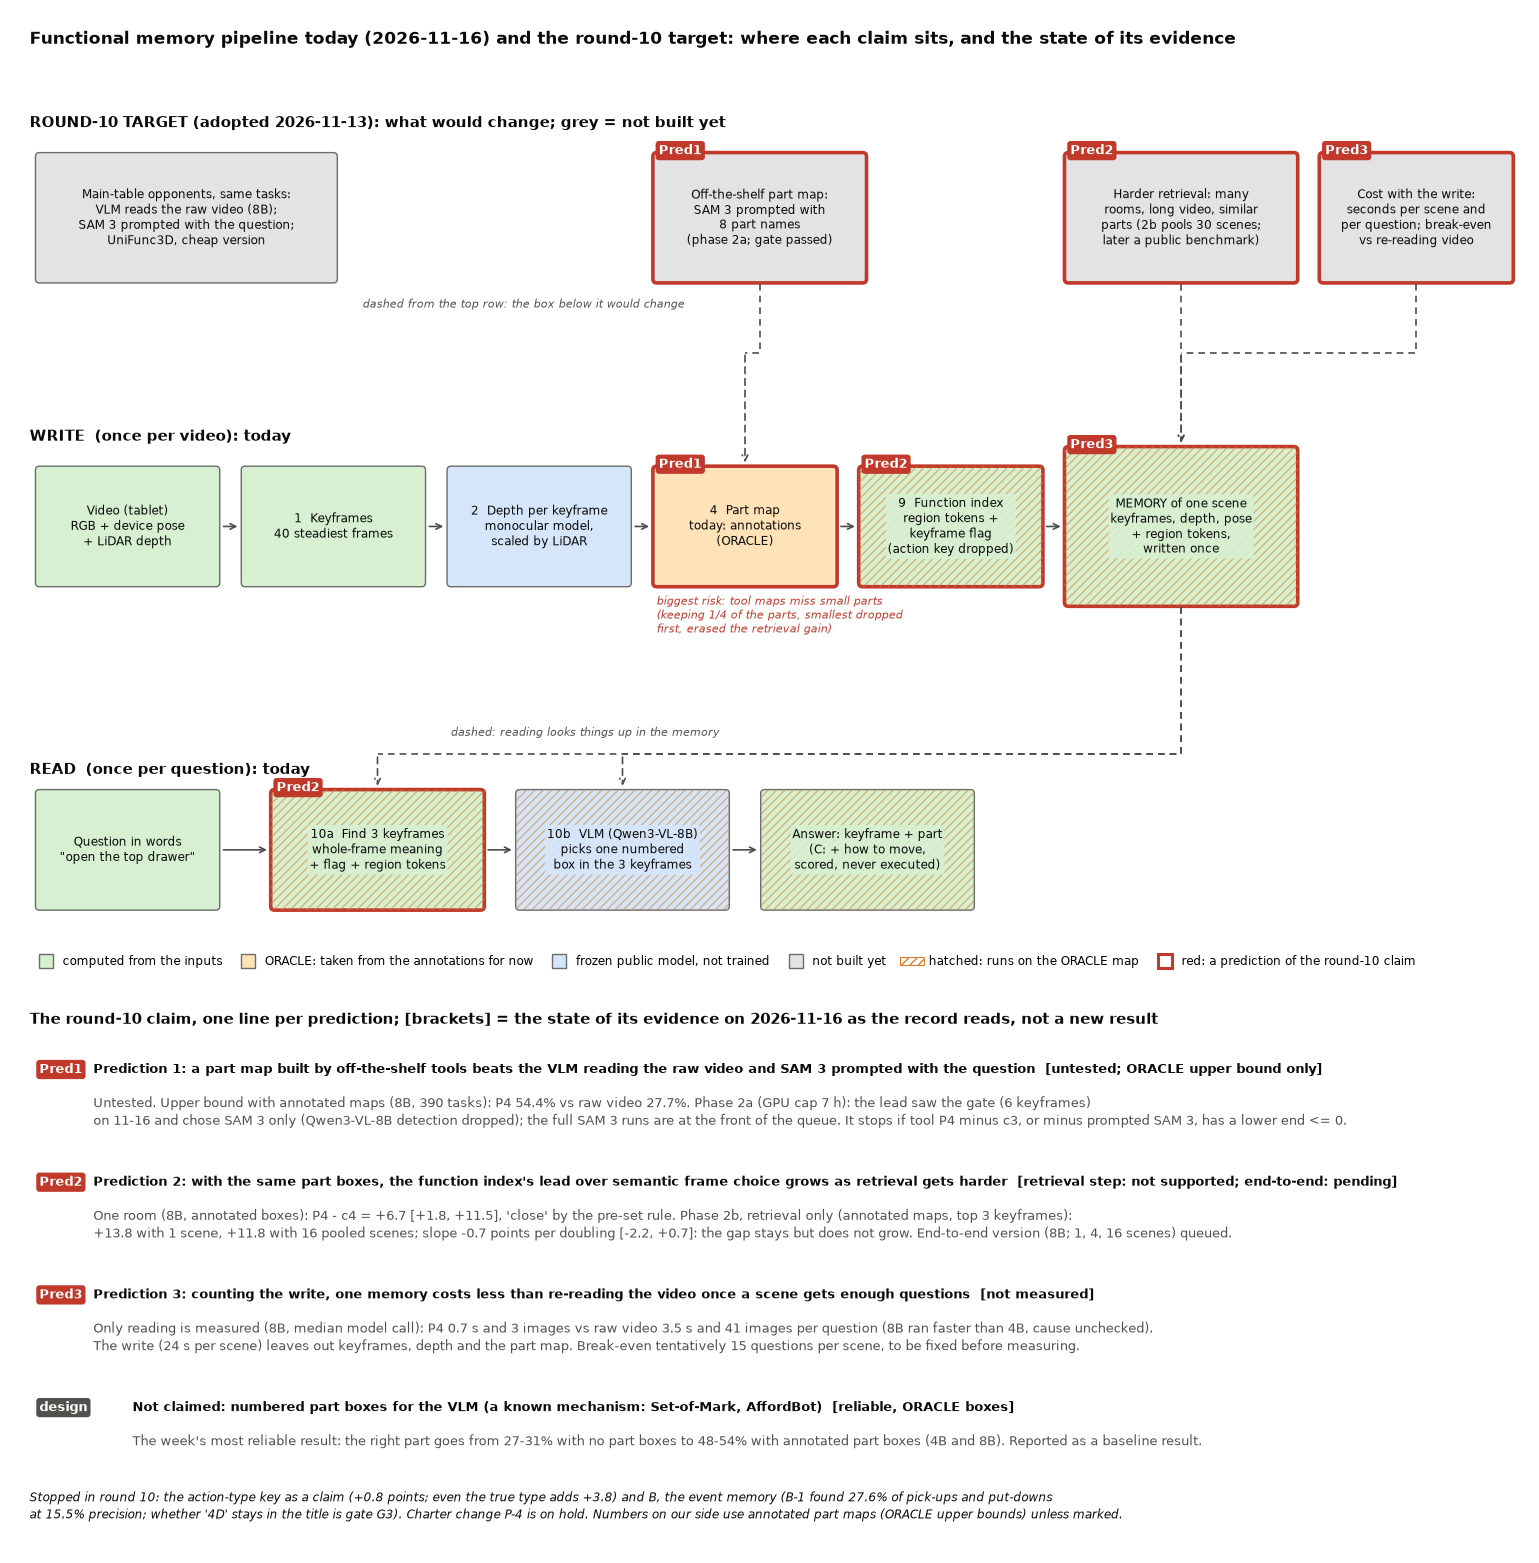

In [6]:
show(FC.draw(FC.CHARTS["now_target_r10"]))

| 标记 | 对应的预测 | 证据现在到哪一步 |
| --- | --- | --- |
| Pred1 | 预测 1：现成工具从视频建出的部件图，交给同一个视觉语言模型，比它直接读原视频、比"用问题文字直接提示 SAM 3"都更准 | **没测。** 阶段 2a 已批（GPU 上限 7 小时）；11-16 你看过示例图，定"a，插到前面"：只用 SAM 3，全部运行已排到前面。只有上限：标注部件图的 P4 54.4% 对直接读原视频 27.7%（8B，§24.8） |
| Pred2 | 预测 2：同样的部件框下，检索越难，功能索引比语义挑画面强得越多 | **检索这一步不支持**（2b，§26）：差一直在（+11.8 到 +17.8），斜率 −0.7 [−2.2, +0.7]。端到端版本排队中（§26.2） |
| Pred3 | 预测 3：把写入算进去，同一个场景问到一定次数之后，写一次的记忆比每次重读视频省 | **没测。** 只量了读：每个问题 P4 0.7 秒、3 张图，读原视频 3.5 秒、41 张图（8B 中位数，只算模型调用）。写入的 24 秒不含选关键帧、单目深度和建部件图。"划算点"暂定 15 个问题，测之前再定 |
| design（不声称） | 编号部件框 | 可靠（4B、8B 一致，约 28% → 约 50%），但别人做过，只当基线结果 |

## 3. 实验结果

每一项按同样的五步写：**问的是什么**；**事先定的规则**（都在跑之前写进讨论稿）；**数字**；**按规则的判定**；**这意味着什么**。

### 3.1 阶段 1（P0–P4）和 §23 的归因检查

**问的是什么：** 记忆预算相同时，token 写在 affordance 区域上（P4），是否比其他写法更常把正确的关键帧排在第一位（预测 A）。五种写法只有"token 写在哪里"不同：P0 只有整帧；P1 均匀网格；P2 随机位置；P3 通用区域（SAM 分出的、不知道哪里能操作的区域）；P4 affordance 区域。打个比方：在一本 40 页的相册里找"能开灯的开关"。P0 一页页看整张照片；P4 事先告诉你哪几页有可操作的东西，并把它们框出来。

**事先定的规则（§21.6，预算为 1 倍）：** "通过"要两条：P4 的"第一个关键帧对"高于 P3，差的区间不含 0；端到端选对部件的比例 P4 不低于 P3。"部分通过"：P4 只高于随机位置 P2。"不通过"：P4 不高于 P2。

**数字（ORACLE，§22.3；Qwen3-VL-4B 读图，阶段 1 的提示词和打分标准）：**

,第一个关键帧对,前 3 个关键帧里有,端到端选对部件（4B）,部件图
写法,,,,
P4 affordance 区域,"66.2% [60.0, 73.3]","84.4% [79.1, 90.1]","53.6% [46.2, 61.6]",标注（ORACLE）
P3 通用区域,"47.3% [39.5, 55.9]","69.2% [61.8, 76.4]","10.3% [7.5, 13.4]",不用部件图
P0 只有整帧,"45.6% [37.4, 54.5]","70.5% [64.3, 77.3]",没有做,不用部件图
P2 随机位置,"38.5% [32.0, 45.6]","64.0% [57.3, 70.8]",没有做,不用部件图


P4 minus P3, first keyframe right: +18.8 [+12.9, +24.9] points; rule category: passed (whether G1 passes is the lead's decision)


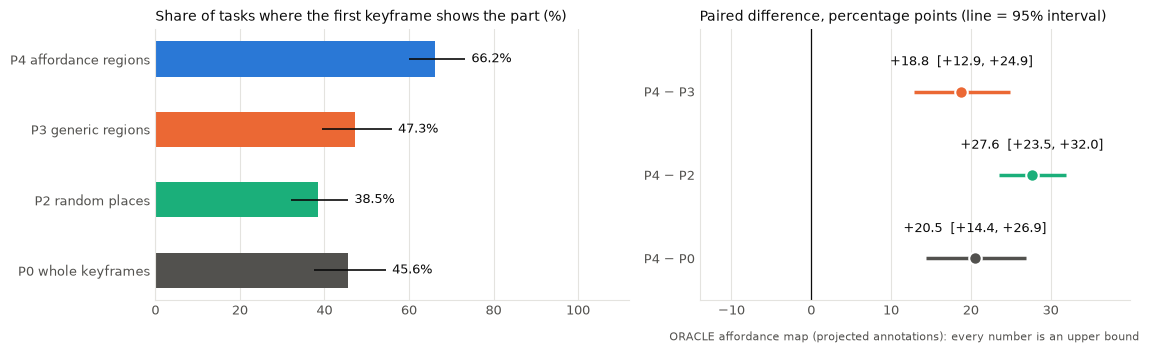

In [7]:
names = {"P4": "P4 affordance 区域", "P3": "P3 通用区域", "P0": "P0 只有整帧", "P2": "P2 随机位置"}
rows = []
for key, label in names.items():
    top3 = get("phase1", "right_keyframe_in_top3", key)
    reading = get("phase1", "reading", {"P4": "P4 affordance regions", "P3": "P3 generic regions"}[key]) if key in ("P4", "P3") else None
    rows.append({"写法": label, "第一个关键帧对": rate(get("phase1", "first_keyframe_right", key)), "前 3 个关键帧里有": rate(top3),
                 "端到端选对部件（4B）": rate(reading) if reading else "没有做", "部件图": "标注（ORACLE）" if key == "P4" else "不用部件图"})
display(pd.DataFrame(rows).set_index("写法"))
print("P4 minus P3, first keyframe right:", diff(get("phase1", "first_keyframe_right", "P4 minus P3")), "points;",
      "rule category:", get("phase1", "rule_21_6_category"), "(whether G1 passes is the lead's decision)")
show(R.headline_figure(D["phase1"]))

**审稿之后加的归因检查（§23，只用 CPU，计划在算之前写定）：** P4 同时得到了两样东西：token 的内容，和"哪些关键帧里有可操作部件"这一帧级标记（下文叫"比特"）。下图把两样分开。带斜线的两组拿到了和 P4 完全相同的关键帧。

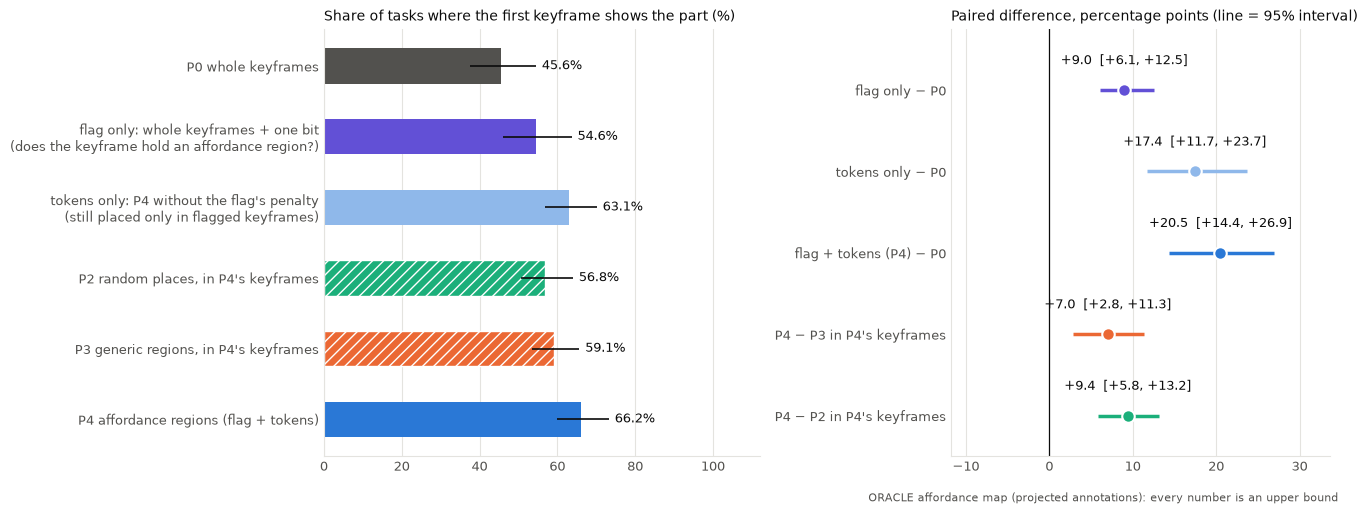

In [8]:
show(R.attribution_figure(D["diag"]))

| 成对比较（第一个关键帧对，ORACLE，§23.3） | 差（个百分点） |
| --- | --- |
| 只用比特（不写任何 token）减 P0 | +9.0 [+6.1, +12.5] |
| 只用 token（去掉空关键帧的扣分）减 P0 | +17.4 [+11.7, +23.7]（仍带着一部分比特的作用） |
| 两样都用（P4）减 P0 | +20.5 [+14.4, +26.9] |
| 同一批关键帧里，P4 减通用区域 | +7.0 [+2.8, +11.3]；token 的权重降到 0.5 或 0.25 时缩到 +1.3 到 +4.9 |

**按规则的判定：** 属于"通过"一档；§23 属于判读表的第一行（帧级信息之外，token 写在 affordance 区域上还有贡献）。你在第 7 轮的回答是"通过，按收窄后的含义"。

**这意味着什么：**
- 在 ORACLE 下，"按功能标记关键帧"本身就值 9 个点。"token 写在哪里"本身约 7 个点，而且随打分方式变化。
- 端到端 53.6% 对 10.3% 的大差距，主要来自"给模型的候选是什么"：给模型看的框里有一个在目标部件上的任务，P4 是 83.6%，P3 只有 20.0%。
- 作为参照，随便挑一张关键帧，对的概率是 9.2%。
- 没成立的：选相机转得慢的帧没有多看到部件（481 个对均匀取帧的 501 个，共 561 个标注部件）；从一张画面现算的接触点，3 厘米以内的只有 38.5%（按 481 个真实部件算，§22.5）。

### 3.2 对照 c：不用记忆，让模型自己找（第一批，§24.1–24.5）

**问的是什么：** 你在第 7 轮要求"使用传统的vlm模型直接读取原video来完成整体系统的对比"。不用我们的记忆，同一个 4B 模型自己找部件，能不能接近 P4？
- **P4：** 记忆挑 3 张关键帧，标注区域加编号框，模型选编号。
- **c3：** 直接读原视频：按时间均匀取 40 帧，模型先挑一帧，再在这一帧的原分辨率上画框。
- **c2：** 记忆挑的 3 张关键帧，没有框，模型一次看 3 张、自己画框。
- **c1：** 按整张画面的语义挑 3 张，没有框，模型自己画框。

**事先定的规则（§24.3）：** 统一的"对"：框的中心落在目标部件上（部件向外放宽 8 个像素）。P4 减某组的区间下沿低于 5 个百分点算"接近"；差本身大于 10、只是区间太宽才低于 5，算"说不清"。c1 或 c3 接近 P4：不用记忆也能做到，停下来讨论。P4 领先：在 ORACLE 下是意料之中，只报告为"阶段 2 有多少余地"。

,给模型看什么,选对部件,选中的画面里有目标,每题秒数（中位数）,每题图数,P4 减这一组,按规则,部件图
组,,,,,,,,
P4,记忆挑的 3 张，标注区域加编号框,"53.1% [45.5, 61.7]",69.2%,1.2,3,—,—,标注（ORACLE，上限）
c3,均匀的 40 帧原视频；先挑帧再画框,"28.5% [23.5, 34.0]",54.4%,5.7,41,"+24.6 [+19.2, +31.5]",落后于 P4,不用（不是上限）
c2,记忆挑的 3 张；一次看 3 张、自己画框,"17.2% [13.4, 21.3]",66.9%,3.2,3,"+35.9 [+29.3, +43.2]",落后于 P4,不用；画面由记忆挑（用到标注的关键帧标记）
c1,按语义挑的 3 张；一次看 3 张、自己画框,"15.1% [11.7, 19.0]",59.2%,3.1,3,"+37.9 [+31.2, +45.4]",落后于 P4,不用（不是上限）


c2 minus c1 (choosing keyframes with the memory, the model draws): +2.1 [−1.1, +5.4] points
c3's 40 even frames show the target in 383 of 390 tasks (98.2%)


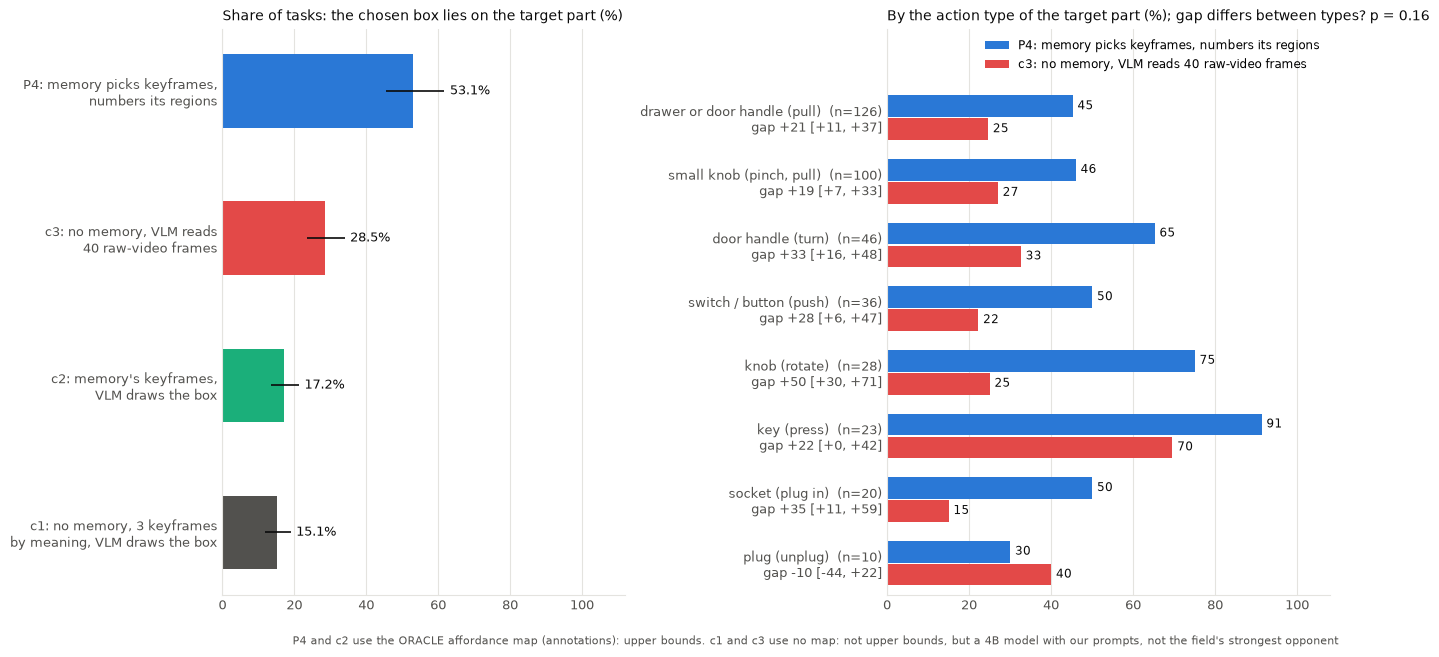

In [9]:
VERDICT = {"behind": "落后于 P4", "close": "接近", "unclear": "说不清"}


def arm_table(summary, arms):
    rows = []
    for arm, label, what, part_map in arms:
        a = summary["arms"][arm]
        against = summary["against_p4"].get(arm)
        rows.append({"组": label, "给模型看什么": what, "选对部件": rate(a["right_part"]), "选中的画面里有目标": f"{100 * a['right_frame']['rate']:.1f}%",
                     "每题秒数（中位数）": a["seconds_per_question"], "每题图数": int(a["images_per_question"]),
                     "P4 减这一组": diff(against) if against else "—",
                     "按规则": VERDICT.get(against["verdict"], against["verdict"]) if against else "—", "部件图": part_map})
    return pd.DataFrame(rows).set_index("组")


ORACLE_MAP, NO_MAP = "标注（ORACLE，上限）", "不用（不是上限）"
MEMORY_FRAMES = "不用；画面由记忆挑（用到标注的关键帧标记）"
display(arm_table(D["c4b"], [
    ("p4n", "P4", "记忆挑的 3 张，标注区域加编号框", ORACLE_MAP),
    ("c3", "c3", "均匀的 40 帧原视频；先挑帧再画框", NO_MAP),
    ("c2", "c2", "记忆挑的 3 张；一次看 3 张、自己画框", MEMORY_FRAMES),
    ("c1", "c1", "按语义挑的 3 张；一次看 3 张、自己画框", NO_MAP)]))
print("c2 minus c1 (choosing keyframes with the memory, the model draws):", diff(get("c4b", "choosing_keyframes")), "points")
print(f"c3's 40 even frames show the target in {get('ceiling', 'shown_in_uniform_frames')} of {get('ceiling', 'tasks')} tasks "
      f"({100 * get('ceiling', 'share'):.1f}%)")
show(R.controls_figure(D["c4b"], D["by_action"]["actions"], between_types_p=get("by_action", "heterogeneity_p4_minus_c3", "p_value")))

图的右半边按目标部件的动作类型拆开，第 3.6 节再讲。

**按规则的判定：** 没有一组"接近"。P4 减 c3 是 +24.6 [+19.2, +31.5]，P4 减 c1 是 +37.9 [+31.2, +45.4]：都"落后于 P4"，只算阶段 2 的余地。c2 减 c1 是 +2.1 [−1.1, +5.4]：只靠记忆挑画面、让模型自己画框，看不出帮助。

**这意味着什么：**
- P4 的领先主要来自**标注给出的部件框**，不能算成记忆的功劳（第 9 轮审稿的阻断项 V-38）。
- c3 低不是因为画面里没有目标：均匀的 40 帧在 98.2% 的任务里看得到目标部件。
- 读法有影响：画面挑对时，c3（先挑一帧、再在原分辨率上画框）框对约 52%（28.5 ÷ 54.4），c2（一次看 3 张直接画）只有约 26%（17.2 ÷ 66.9）。所以第 9 轮又补了 c1'、c2'（第 3.4 节）。

### 3.3 第二批：a、b、d、c+（4B，§24.7）

**问的是什么：**
- **a（只做检索）：** 把全部通用区域、或全部网格档位都写进记忆，能不能在检索上追上 P4？
- **b：** P3 的通用区域用 5 个随机种子，和 P4 同样的读法、中性提示词。
- **d：** 在全部通用区域里得分最高的 40 个上加编号框，模型挑。
- **c+：** 不用记忆，把我们挑的 40 张关键帧给模型，先挑一张再画框（读法同 c3）。

**事先定的规则：** 沿用 §24.3。a 接近 P4 说明"全写进去也行"，P4 只赢在存得少；c+ 减 c3 是"我们挑的关键帧"对"均匀取帧"的价值，不算记忆的价值。

,给模型看什么,选对部件,选中的画面里有目标,每题秒数（中位数）,每题图数,P4 减这一组,按规则,部件图
组,,,,,,,,
P4,记忆挑的 3 张，标注区域加编号框,"53.1% [45.5, 61.7]",69.2%,1.20,3,—,—,标注（ORACLE，上限）
c+,我们挑的 40 张关键帧；先挑帧再画框,"26.4% [21.9, 31.7]",52.3%,4.40,41,"+26.7 [+20.8, +33.5]",落后于 P4,不用（不是上限）
d,记忆挑的 3 张上得分最高的 40 个通用区域,"14.1% [11.4, 17.1]",55.4%,0.80,3,"+39.0 [+31.3, +47.5]",落后于 P4,不用（通用区域）
b,和 P4 一样多的通用区域（5 个种子）,"11.4% [8.4, 15.0]",48.0%,0.84,3,"+41.6 [+34.5, +50.3]",落后于 P4,不用（通用区域）


,第一个关键帧对,每个场景的 token（中位数）,P4 减这一组
记忆里写什么,,,
P4 affordance 区域,"66.2% [60.0, 73.3]",63,—
a：全部网格档位,"53.6% [45.3, 62.2]",2960,"+12.6 [+6.1, +18.7]"
a：全部通用区域,"50.0% [44.1, 56.2]",2265,"+16.2 [+11.4, +21.7]"
P3 通用区域（1 倍）,"47.4% [39.9, 55.7]",63,—
P0 只有整帧,"45.6% [37.4, 54.5]",0,—


c+ minus c3 (our keyframes vs even frames, no memory): −2.1 [−6.6, +2.7] points


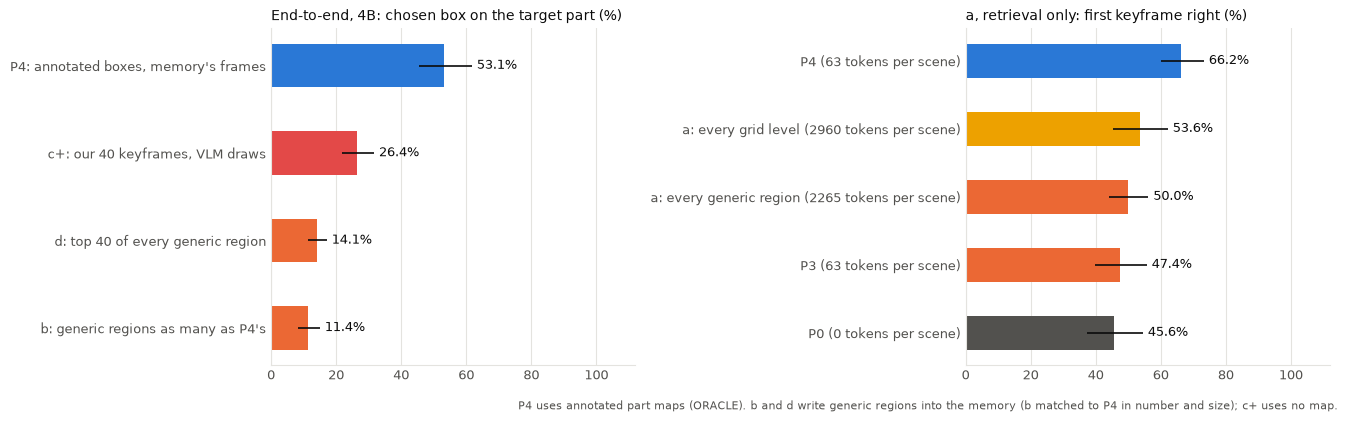

In [10]:
display(arm_table(D["c4b"], [
    ("p4n", "P4", "记忆挑的 3 张，标注区域加编号框", ORACLE_MAP),
    ("cplus", "c+", "我们挑的 40 张关键帧；先挑帧再画框", NO_MAP),
    ("d", "d", "记忆挑的 3 张上得分最高的 40 个通用区域", "不用（通用区域）"),
    ("b", "b", "和 P4 一样多的通用区域（5 个种子）", "不用（通用区域）")]))
a_names = {"P4": "P4 affordance 区域", "a: every grid level": "a：全部网格档位", "a: every generic region": "a：全部通用区域",
           "P3": "P3 通用区域（1 倍）", "P0": "P0 只有整帧"}
display(pd.DataFrame([{"记忆里写什么": label, "第一个关键帧对": rate(get("a", "arms", key)),
                       "每个场景的 token（中位数）": int(get("a", "arms", key, "tokens_per_scene")),
                       "P4 减这一组": diff(get("a", "against_p4", key)) if key.startswith("a:") else "—"}
                      for key, label in a_names.items()]).set_index("记忆里写什么"))
print("c+ minus c3 (our keyframes vs even frames, no memory):", diff(get("c4b", "our_keyframes_vs_even_frames")), "points")
rows = {arm: get("c4b", "arms", arm, "right_part") for arm in ("p4n", "cplus", "d", "b")}
a_rows = {key: get("a", "arms", key) for key in a_names}
fig, (left, right) = plt.subplots(1, 2, figsize=(13.5, 4.2))
R._rate_bars(left, rows, list(rows), ["P4: annotated boxes, memory's frames", "c+: our 40 keyframes, VLM draws",
                                      "d: top 40 of every generic region", "b: generic regions as many as P4's"], [BOX, NOBOX, GENERIC, GENERIC])
left.set_title("End-to-end, 4B: chosen box on the target part (%)", fontsize=10, loc="left", color=INK)
R._rate_bars(right, a_rows, list(a_rows), [f"{key} ({int(a_rows[key]['tokens_per_scene'])} tokens per scene)"
                                           for key, label in a_names.items()], [BOX, R.POLICY_COLOUR[R.A.P1], GENERIC, GENERIC, MUTED])
right.set_title("a, retrieval only: first keyframe right (%)", fontsize=10, loc="left", color=INK)
fig.tight_layout(rect=(0, 0.04, 1, 1))
R._oracle_note(fig, "P4 uses annotated part maps (ORACLE). b and d write generic regions into the memory (b matched to P4 in number and size); c+ uses no map.")
show(fig)

*（上图只画了端到端的四组；检索那一组 a 见上面第二张表。）*

**按规则的判定：** 四组都"落后于 P4"。c+ 减 c3 是 −2.1 [−6.6, +2.7]。a：全部网格档位 53.6%、全部通用区域 50.0%，都低于 P4 的 66.2%（ORACLE）。

**这意味着什么：** 在 ORACLE 下，标注的部件框比任何通用区域的框都好得多，不论只放和 P4 一样多（b）还是全部写进去（d）。P4 不只存得少（每个场景约 63 个 token，对两三千个），检索也更准。把均匀帧换成我们挑的关键帧，对直接读画面的模型没有帮助。

### 3.4 c4、c1'、c2'，以及换成 8B（§24.8）

**问的是什么：** 记忆本身值多少。
- **c4：** 同样的标注框，但画面不用记忆挑，而是按整张画面的语义挑 3 张（c1 的画面）。P4 减 c4 是"记忆挑画面"的价值（仍是上限：记忆挑画面时用到了标注的关键帧标记）。
- **c1'、c2'：** c1、c2 改用 c3 的读法（先挑一张，再在原分辨率上画框）。c2' 减 c1' 是同一种读法下"挑画面"的价值。
- **8B：** 换成 2026 年论文里默认的 Qwen3-VL-8B，在 390 个任务上把这几组都再跑一遍。

**事先定的规则（4B、8B 各读一次）：** P4 减 c4 的区间下沿低于 5 个百分点记为"接近"：第 9 轮选的方案乙以"按功能建索引"为重心，所以停下来讨论。c2' 减 c1' 的区间下沿大于 0 记为"有价值"，否则"看不出"。8B 的 c1 或 c3 接近 P4：停下来讨论。

Qwen3-VL-8B (4B for comparison):


,给模型看什么,4B 的结果,8B 减 4B,选对部件,选中的画面里有目标,每题秒数（中位数）,每题图数,P4 减这一组,按规则,部件图
组,,,,,,,,,,
P4,记忆挑的 3 张，标注区域加编号框,53.1%,"+1.3 [−2.7, +5.1]","54.4% [47.1, 62.6]",68.5%,0.7,3,—,—,标注（ORACLE，上限）
c4,按语义挑的 3 张，标注区域加编号框,48.7%,"−1.0 [−4.4, +2.3]","47.7% [40.9, 55.3]",60.5%,0.6,3,"+6.7 [+1.8, +11.5]",接近,标注（ORACLE，上限）
c2',记忆挑的 3 张；先挑一张再画框,30.8%,"+0.0 [−3.6, +4.0]","30.8% [26.1, 36.6]",65.6%,1.7,4,"+23.6 [+18.2, +29.5]",落后于 P4,不用；画面由记忆挑（用到标注的关键帧标记）
c3,均匀的 40 帧原视频；先挑帧再画框,28.5%,"−0.8 [−5.6, +5.0]","27.7% [22.6, 33.0]",58.5%,3.5,41,"+26.7 [+21.5, +32.7]",落后于 P4,不用（不是上限）
c1',按语义挑的 3 张；先挑一张再画框,27.2%,"+0.0 [−3.8, +3.9]","27.2% [21.9, 33.3]",54.1%,1.7,4,"+27.2 [+21.3, +33.6]",落后于 P4,不用（不是上限）
c1,按语义挑的 3 张；一次看 3 张、自己画框,15.1%,"−3.3 [−6.0, −0.8]","11.8% [8.7, 15.2]",58.7%,2.2,3,"+42.6 [+35.4, +50.5]",落后于 P4,不用（不是上限）


c2' minus c1' (choosing keyframes, same reading):  4B +3.6 [−0.9, +8.1]   8B +3.6 [−0.8, +8.2]


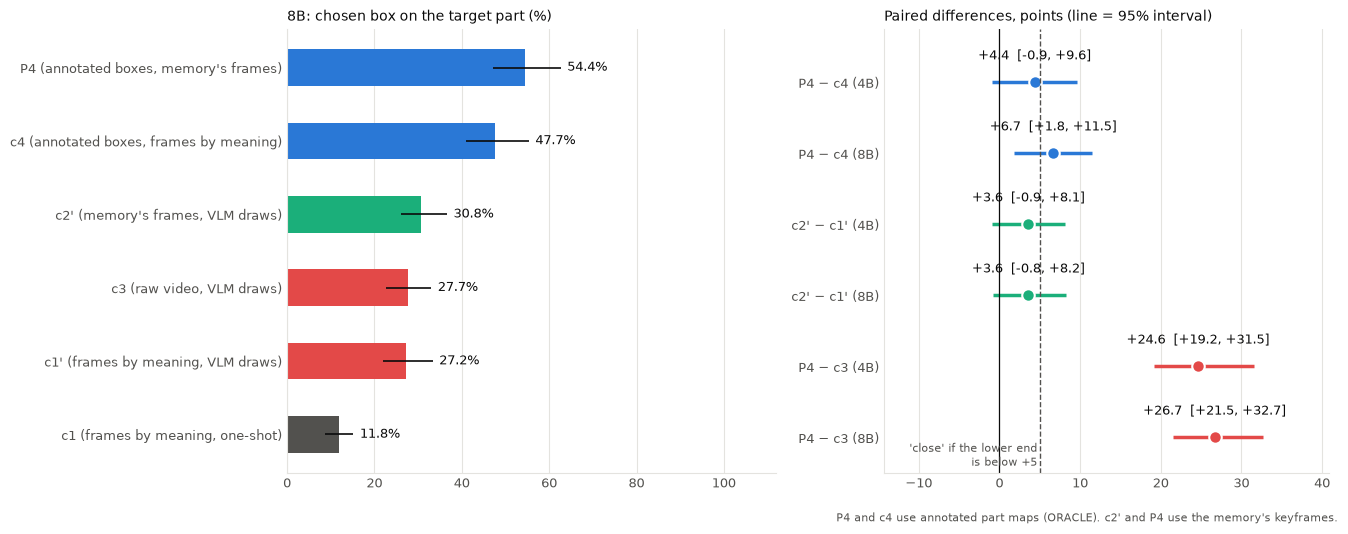

In [11]:
arms8 = [("p4n", "P4", "记忆挑的 3 张，标注区域加编号框", ORACLE_MAP),
         ("c4", "c4", "按语义挑的 3 张，标注区域加编号框", ORACLE_MAP),
         ("c2s", "c2'", "记忆挑的 3 张；先挑一张再画框", MEMORY_FRAMES),
         ("c3", "c3", "均匀的 40 帧原视频；先挑帧再画框", NO_MAP),
         ("c1s", "c1'", "按语义挑的 3 张；先挑一张再画框", NO_MAP),
         ("c1", "c1", "按语义挑的 3 张；一次看 3 张、自己画框", NO_MAP)]
table8 = arm_table(D["c8b"], arms8)
table8.insert(1, "4B 的结果", [f"{100 * get('c4b', 'arms', arm, 'right_part', 'rate'):.1f}%" for arm, *_ in arms8])
table8.insert(2, "8B 减 4B", [diff(get("c8b", "against_4b", arm)) for arm, *_ in arms8])
print("Qwen3-VL-8B (4B for comparison):")
display(table8)
print("c2' minus c1' (choosing keyframes, same reading):  4B", diff(get("c4b", "choosing_keyframes_same_reading")),
      "  8B", diff(get("c8b", "choosing_keyframes_same_reading")))
diffs = {"P4 − c4 (4B)": get("c4b", "against_p4", "c4"), "P4 − c4 (8B)": get("c8b", "against_p4", "c4"),
         "c2' − c1' (4B)": get("c4b", "choosing_keyframes_same_reading"), "c2' − c1' (8B)": get("c8b", "choosing_keyframes_same_reading"),
         "P4 − c3 (4B)": get("c4b", "against_p4", "c3"), "P4 − c3 (8B)": get("c8b", "against_p4", "c3")}
rows = {arm: get("c8b", "arms", arm, "right_part") for arm in ("p4n", "c4", "c2s", "c3", "c1s", "c1")}
show(bars_and_differences(
    rows, list(rows), ["P4 (annotated boxes, memory's frames)", "c4 (annotated boxes, frames by meaning)", "c2' (memory's frames, VLM draws)",
                       "c3 (raw video, VLM draws)", "c1' (frames by meaning, VLM draws)", "c1 (frames by meaning, one-shot)"],
    [BOX, BOX, MEMORY, NOBOX, NOBOX, R.POLICY_COLOUR[R.A.P0]], diffs, list(diffs), list(diffs),
    [BOX, BOX, MEMORY, MEMORY, NOBOX, NOBOX], "8B: chosen box on the target part (%)", "Paired differences, points (line = 95% interval)",
    "P4 and c4 use annotated part maps (ORACLE). c2' and P4 use the memory's keyframes.", rule_at=5,
    rule_text="'close' if the lower end\nis below +5"))

**按规则的判定：**
- **c4 接近 P4，4B 和 8B 都是：** 4B +4.4 [−0.9, +9.6]，8B +6.7 [+1.8, +11.5]。8B 的区间下沿大于 0 但低于 5：记忆挑画面有一点用，但不到"明显不接近"的程度。按规则停下讨论，这就是第 10 轮评估的起点。
- **c2' 减 c1'：** 4B +3.6 [−0.9, +8.1]，8B +3.6 [−0.8, +8.2]：同一种读法下，记忆挑画面看不出价值。
- **8B 没有接近 P4 的不用记忆的组。** 换成 8B 几乎没有变化：各组 8B 减 4B 都在 ±3.3 个百分点以内。c1'、c2' 的 4B、8B 总数恰好相同，记录里核对过：780 个答案全都不一样，只是总数巧合（§24.8）。

**这意味着什么：** 不论 4B 还是 8B，P4 比直接读原视频高出的约 25 个百分点，几乎都来自"有部件的框"（affordance map 本身），而不是记忆挑画面。按事先的规则，这一条让第 9 轮的方案乙（以按功能建索引为重心）失去了大半支撑。

**时间（只算模型调用，中位数，不含写入）：** 8B 的 P4 每题 0.7 秒、3 张图；c3 3.5 秒、41 张图。4B 的 P4 1.2 秒、c3 5.7 秒。8B 反而比 4B 快，原因没查（可能是不同的卡、不同的负载），这些时间只能粗看。

### 3.5 R7-B：漏检和误检的模拟（§24.6）

**问的是什么：** 自己建的部件图会漏掉部件（漏检），也会把不能操作的地方当成部件（误检）。漏多少、错多少以内，按功能建的记忆在检索上仍然比通用区域好？只用 CPU，扰动的是标注。

**事先定的规则：** 每一格和 P3（通用区域，47.4%）成对比较：区间下沿大于 0 记为"明显好于 P3"。**门槛：** 误检为真部件数的 0.5 倍时，从留 100% 往下，一直明显好于 P3 的最低留存比例。如果留 100%、误检 0.5 倍时已经不明显好于 P3，说明对误检很敏感。

**数字：** 下图上排是事先写定的规则；下排是第 9 轮第 2 次审稿后的更严的重算（中心落在任何部件上的通用区域都不算误检；规则在算之前写定）。格子里是"第一个关键帧对"的比例，标"= P3"的格子不明显好于 P3。

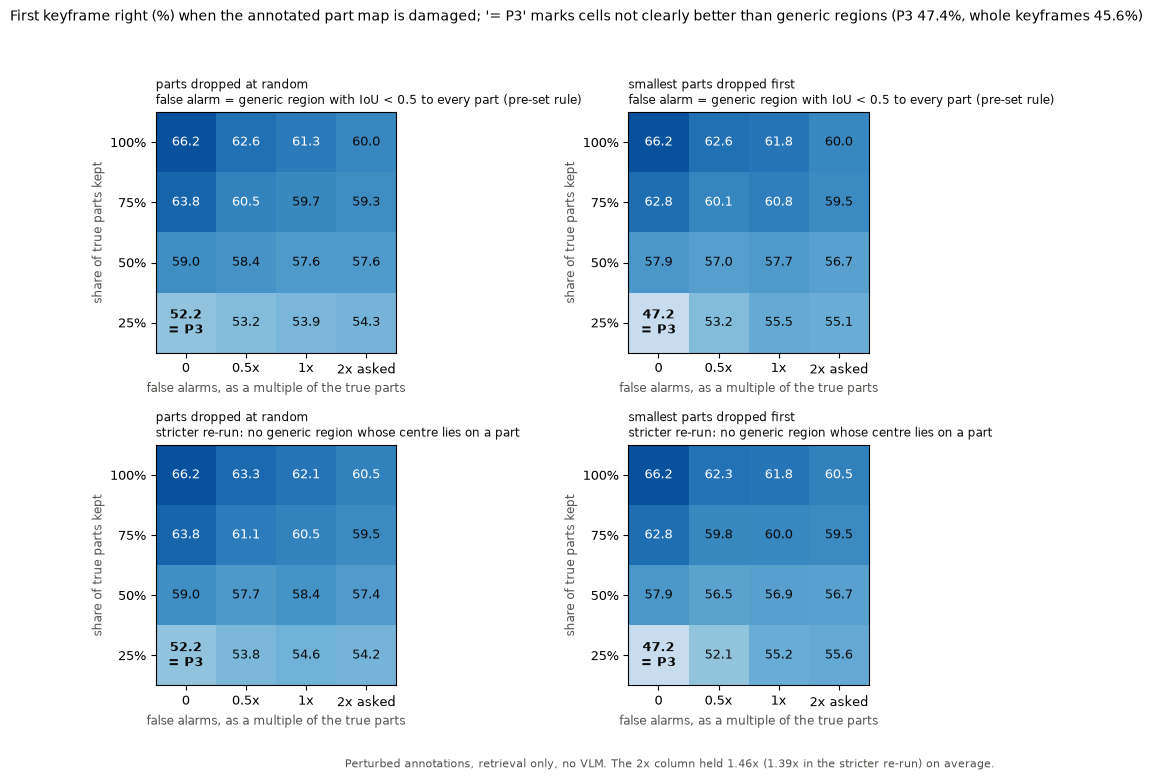

kept 100%, false alarms 0.5x, minus P3: +15.2 [+10.4, +20.3] points; thresholds (pre-set rule): {'random': 0.25, 'smallest_first': 0.25} ; stricter re-run: {'random': 0.25, 'smallest_first': 0.25}


In [12]:
show(map_error_figure(D["errors"], D["errors_centre"]))
cell = get("errors", "grid", "random", "1", "0.5")
print("kept 100%, false alarms 0.5x, minus P3:", diff(cell["against_p3"]), "points;",
      "thresholds (pre-set rule):", get("errors", "threshold_keep_share"), "; stricter re-run:", get("errors_centre", "threshold_keep_share"))

**按规则的判定：** 两种丢法的门槛都是 25%，也就是试到的最低一档。留 100%、误检 0.5 倍时仍明显好于 P3（+15.2 [+10.4, +20.3]），按读法记为"在检索这一步对误检不敏感"。更严的重算结论不变（留 100%、误检 0.5 倍：随机丢 63.3%、先丢小的 62.3%，原来都是 62.6%）。

**这意味着什么：**
- 在检索这一步，**漏检比误检要紧**：误检到 1 倍时少 4 到 5 个百分点；漏掉一半部件时少 7 到 8 个；先丢小的、只剩四分之一时（47.2%），和 P3 看不出差别。
- 措辞要窄（第 10 轮评估的审稿 V-73）："对误检不敏感"只指检索这一步、误检和部件一样大的时候，而且一部分来自"空关键帧扣 3 分"这个常数（只留 25% 时加误检分数反而上升）。读图那一步对误检可能敏感得多：b、d 在通用区域的框里挑，只有 11% 到 14%。
- 真实工具的误检常常是整个物体的大框，这里模拟不到；要靠阶段 2a 的真实输出来量。

### 3.6 动作类型：差距在动作类型之间是否不同（p = 0.16），和按动作类型检索（§24.5、§24.10）

**问的是什么：** 你在第 7 轮写过，希望"一些关于action的方向上又格外高的performance"。两个检查：
1. **检验（§24.5，规格之外，计算前写定）：** P4 对 c3 的差距（第 3.2 节图的右半边），在动作类型之间是否真的不同。在每个场景内部打乱动作标签 10,000 次，看实际的离散程度是否大于随机分组。规则：p < 0.05 记为"确实不同"，否则"看不出不同"。
2. **动作键检索（§24.10，只用 CPU，上限）：** 给每个区域加一个"功能的键"（例如 "rotate a knob or a dial"），检索时按任务文字匹配这个键。五组：不加键（就是 P4）、动作短语、只有部件词、只有动词、真值动作类型（按真值筛选的上限）。规则：动作短语减不加键的区间下沿大于 0 记为"有用"；真值减不加键本身不到 5 个百分点，记为"按动作类型检索的余地很小"。

test: 389 tasks, 8 action types, 10,000 shuffles within scenes, p = 0.159


,第一个关键帧对,减不加键
检索键,,
no key (= P4),"66.2% [60.0, 73.3]",—
action phrase,"66.9% [60.7, 74.0]","+0.8 [−0.9, +2.4]"
part words only,"66.7% [60.1, 74.4]","+0.5 [−1.1, +2.3]"
verb only,"66.7% [60.9, 73.6]","+0.5 [−0.6, +1.7]"
true action type (upper bound),"70.0% [63.4, 77.5]","+3.8 [+0.9, +7.5]"


verb only minus part words only: +0.0 [−2.4, +2.2] points


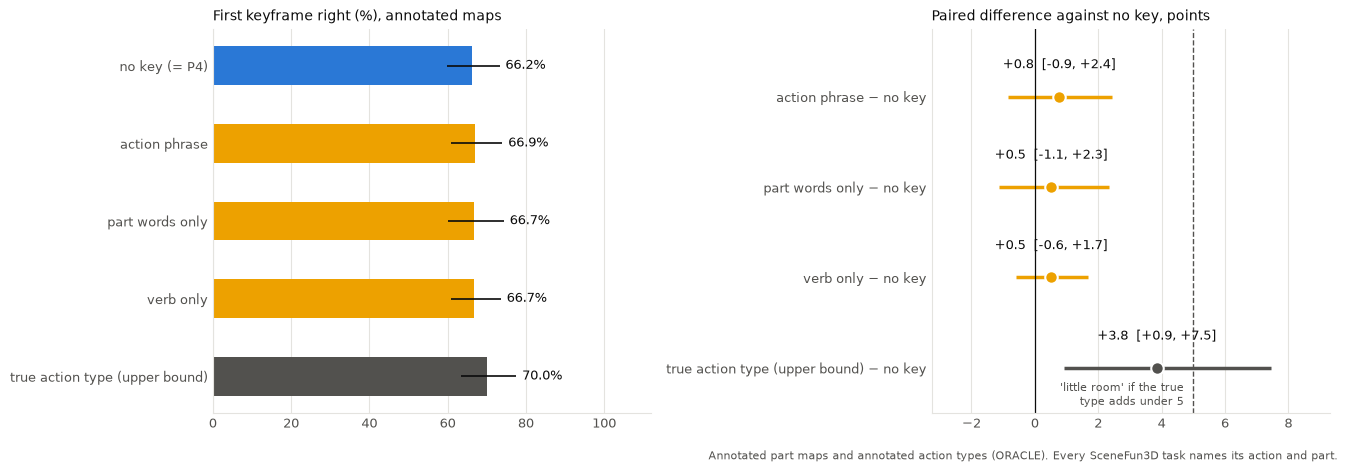

In [13]:
het = get("by_action", "heterogeneity_p4_minus_c3")
print(f"test: {het['tasks']} tasks, {het['action_types']} action types, {het['shuffles']:,} shuffles within scenes, p = {het['p_value']:.3f}")
key_names = {"no key": "no key (= P4)", "action phrase": "action phrase", "part words only": "part words only", "verb only": "verb only",
             "true type": "true action type (upper bound)"}
rows = {key: get("key", "arms", key) for key in key_names}
against = {key: get("key", "against_no_key", key) for key in key_names if key != "no key"}
display(pd.DataFrame([{"检索键": label, "第一个关键帧对": rate(rows[key]), "减不加键": diff(against[key]) if key in against else "—"}
                      for key, label in key_names.items()]).set_index("检索键"))
print("verb only minus part words only:", diff(get("key", "verb_minus_part")), "points")
show(bars_and_differences(
    rows, list(rows), list(key_names.values()), [BOX, "#eda100", "#eda100", "#eda100", MUTED], against, list(against),
    [f"{key_names[k]} − no key" for k in against], ["#eda100", "#eda100", "#eda100", MUTED],
    "First keyframe right (%), annotated maps", "Paired difference against no key, points", "Annotated part maps and annotated action "
    "types (ORACLE). Every SceneFun3D task names its action and part.", rule_at=5, rule_text="'little room' if the true\ntype adds under 5"))

**按规则的判定：** 检验 p = 0.16（389 个任务、8 个动作类型），记为"看不出不同"。动作短语 +0.8 [−0.9, +2.4]，记为"看不出有用"；真值 +3.8 [+0.9, +7.5]，不到 5 个点，记为"余地很小"；动词和部件词没有差别（0.0 [−2.4, +2.2]）。

**这意味着什么：**
- SceneFun3D 的每个任务都点明了动作和部件（"Rotate the knob…"），所以按语义检索本身已经带上了动作的信息；动作类型又几乎就是部件类型（转的是旋钮、拉的是拉手）。
- 第 10 轮你选了 (b)：在 2b 里再加一组，看相似部件多时动作键有没有用。结果也没有用（第 3.7 节）。所以按评估，"按动作类型检索"不再当主张，动作方向改由 C（能直接拿去做的回答）来体现。

### 3.7 阶段 2b：把多个场景的关键帧混在一起检索（§26）

**问的是什么：** 预测 2 的第一步：检索变难时，功能索引挑画面比语义挑画面强多少，这个差是否随难度变大。做法：对每个目标场景，把它的 40 张关键帧和另外 K − 1 个场景的关键帧混成一个记忆（K = 1、2、4、8、16；别的场景随机抽 5 次）。目标场景的任务只能在目标场景里找到对的；混进来的场景带来更多同类的部件（别的抽屉、别的开关）。两边用同样的标注部件图，只是挑画面的办法不同。

**事先定的规则：** 看"前 3 张里有没有对的"（读图那一步看的就是前 3 张）。功能索引减语义的差对 log2 K 的斜率，区间下沿大于 0，而且 K = 16 时差本身至少 5 个百分点，才算"支持"。动作键那一组同样读法。

,同动作类型的标注区域（中位数）,语义,功能索引,功能索引 + 动作键,功能索引减语义,动作键减功能索引
K（混进来的场景数）,,,,,,
1,16,"70.5% [64.3, 77.3]","84.4% [79.1, 90.1]","84.4% [78.9, 90.2]","+13.8 [+8.7, +19.2]","+0.0 [−1.7, +1.7]"
2,28,"59.9% [52.7, 67.2]","77.8% [73.1, 82.8]","76.9% [71.7, 82.6]","+17.8 [+12.8, +23.0]","−0.9 [−2.8, +0.9]"
4,71,"51.0% [43.3, 59.1]","68.2% [62.7, 74.0]","67.4% [61.8, 73.1]","+17.2 [+12.7, +21.9]","−0.8 [−3.0, +1.2]"
8,143,"40.9% [33.5, 48.9]","56.0% [49.9, 62.7]","55.3% [49.1, 61.9]","+15.1 [+11.0, +19.3]","−0.7 [−3.6, +1.7]"
16,283,"32.7% [25.3, 40.3]","44.6% [38.8, 51.2]","45.1% [38.5, 51.5]","+11.8 [+8.3, +15.7]","+0.5 [−2.0, +2.6]"


function index minus semantic: slope −0.7 [−2.2, +0.7] points per doubling, gap at K = 16 +11.8, supported: False
function index + action key minus function index: slope +0.1 [−0.7, +0.9] points per doubling, gap at K = 16 +0.5, supported: False


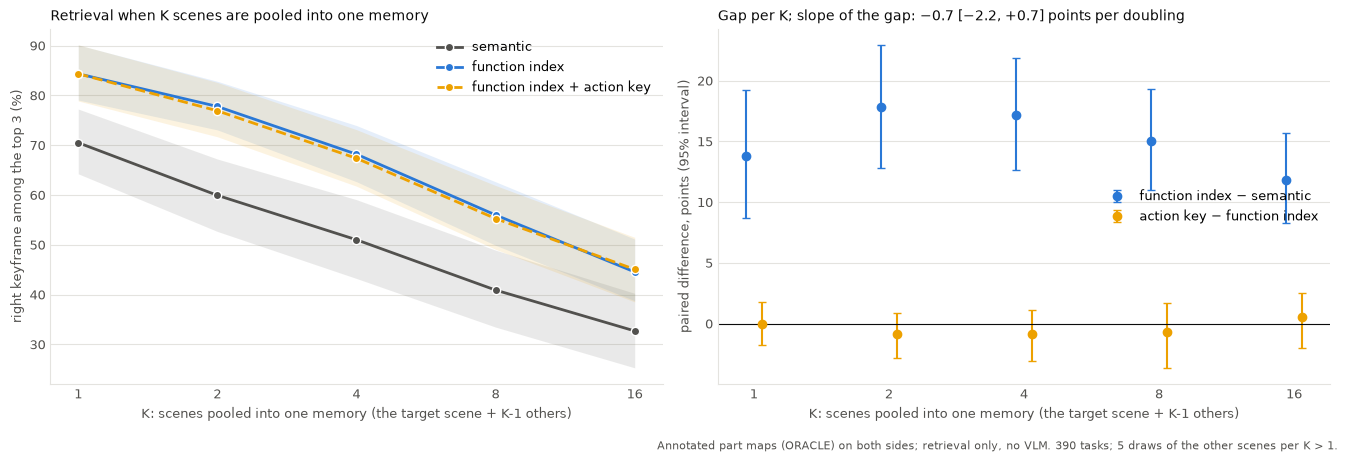

In [14]:
rows = []
for k in get("pooled", "pool_sizes"):
    per = get("pooled", "per_size", str(k))
    rows.append({"K（混进来的场景数）": k, "同动作类型的标注区域（中位数）": round(per["median_same_type_regions"]),
                 "语义": rate(per["semantic"]["top3"]), "功能索引": rate(per["function index"]["top3"]),
                 "功能索引 + 动作键": rate(per["function index + action key"]["top3"]),
                 "功能索引减语义": diff(per["function index minus semantic (top3)"]),
                 "动作键减功能索引": diff(per["function index + action key minus function index (top3)"])})
display(pd.DataFrame(rows).set_index("K（混进来的场景数）"))
for name, reading in get("pooled", "readings").items():
    print(f"{name}: slope {diff(reading['slope_per_doubling'])} points per doubling, gap at K = 16 "
          f"{100 * reading['gap_at_largest']:+.1f}, supported: {reading['supported']}")
show(pooled_figure(D["pooled"]))

**按规则的判定：** 斜率 −0.7 [−2.2, +0.7]，区间包含 0：**预测 2 的第一步在检索这一步不支持。** 差一直在（+11.8 到 +17.8），但不随难度变大。动作键那一组斜率 +0.1 [−0.7, +0.9]，K = 16 时 +0.5：相似部件多时也没有用。

**这意味着什么：**
- 只作描述：检索这一步，功能索引在每个 K 都多找到 12 到 18 个百分点的对画面。但在单个房间里，读图那一步有了部件框就把这个差抹掉了大半（c4，第 3.4 节）。K 变大时，语义挑的前 3 张里常常一张对的都没有（K = 16 时有对的只占 32.7%），读图就补不回来。所以端到端的差会不会随 K 变大，这次没测。
- **局限：** 混进来的是别的房间，房间本身的样子会帮语义检索把它们分开，比"同一个长视频里的相似部件"容易；标注的部件图，是上限。
- **这就是 §26.2 端到端版本的来由。** 它是第一步没过之后才加的检查，§26.2 和账本都写明了这一点：8B 读编号框，K = 1、4、16，每个 K 一组抽样；斜率区间下沿大于 0 且 K = 16 时差至少 5 个点，记为"端到端支持预测 2"，否则按评估第 10 节到关口 G2。K = 1 应当接近 8B 的 P4 和 c4（54.4%、47.7%），作为核对。现在排在你的作业后面。

### 3.8 B-0、B-1：HD-EPIC 上问"做过什么"的头两步（§25.1、§25.2、§25.4）

**问的是什么：** B 是"做过什么"类的问题（例如"抽屉开了几次""这个物体被挪到了哪里"）。你在第 8 轮说"希望能够同时做B"以便平行比较。头两步只用 CPU，在厨房 P02 上：
- **B-0：** HD-EPIC 的 242 道题能不能对上标注里的事件，用论文的规则能不能重新算出答案。
- **B-1：** 不用标注，只靠 Aria 眼镜算出的手掌位置（第 9 轮你回答"可以"当输入），能不能找出"拿起、放下"的时刻。

**事先定的规则：** B-0：至少 90% 的题对得上、规则算出的答案至少 90% 对，才往下走；否则是数据问题，先修数据。B-1：精度至少 50% 时召回至少 60% 才往 B-2 走；否则不用标注的事件需要 GPU 上用画面的检测器，B 的代价要由你重新和 A、C 比。

,对上标注事件的题,规则答案对,判定
运行,,,
B-0 按写定的规则,41/242 (16.9%),6/54 (11.1%),数据问题
B-0 框的横纵坐标换过来（看到结果后加的修补）,228/242 (94.2%),51/54 (94.4%),"你接受后记为通过（""1 接受""）"


B-1: 3,593 annotated pick-ups and put-downs, 6,383 detections; recall 27.6%, precision 15.5% (bar: recall >= 60% at precision >= 50%) -> fail
     detections shifted by 15 s (chance): recall 12.4%, precision 7.0%
     a tracked palm within 30 cm of the object at the annotated moment: 52% of all annotated moments (2,494 have a palm reading, 74.9% of those)
     alignment check: wearer-to-object distance error, median 1.9 cm at offset 0 (best offset 0.0 s)


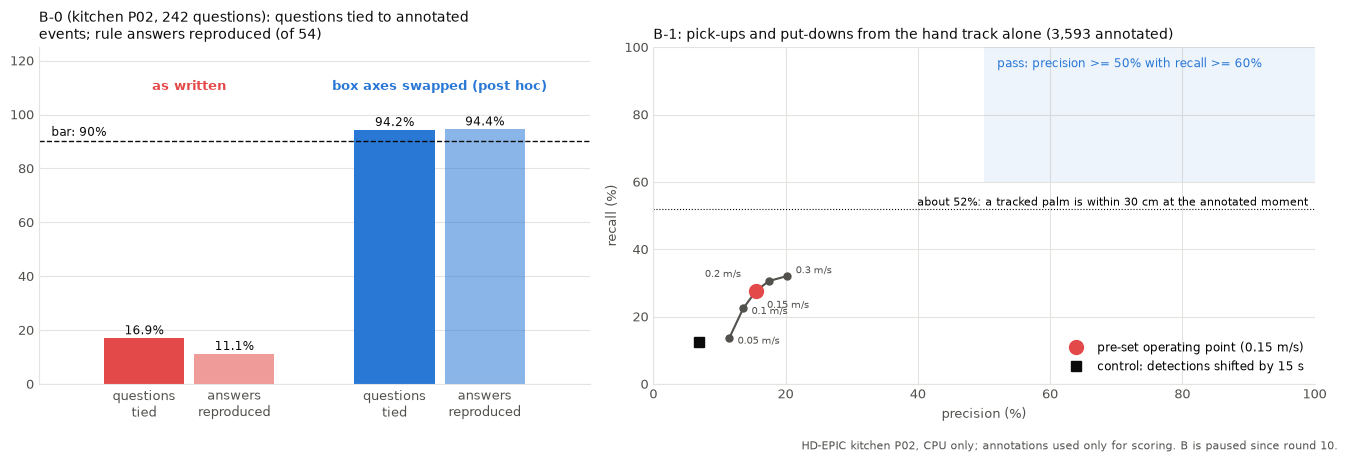

In [15]:
b0, b0s, b1 = get("b0", "summary"), get("b0_swapped", "summary"), get("b1", "summary")
display(pd.DataFrame([
    {"运行": "B-0 按写定的规则", "对上标注事件的题": f"{b0['tied']}/{b0['questions']} ({100 * b0['tied_share']:.1f}%)",
     "规则答案对": f"{b0['reproduced']}/{b0['rule_questions']} ({100 * b0['reproduced_share']:.1f}%)", "判定": "数据问题"},
    {"运行": "B-0 框的横纵坐标换过来（看到结果后加的修补）", "对上标注事件的题": f"{b0s['tied']}/{b0s['questions']} ({100 * b0s['tied_share']:.1f}%)",
     "规则答案对": f"{b0s['reproduced']}/{b0s['rule_questions']} ({100 * b0s['reproduced_share']:.1f}%)", "判定": "你接受后记为通过（\"1 接受\"）"}]).set_index("运行"))
ceiling = b1["palm_within_30cm_at_0"] * b1["clock_check_palm_to_object"]["n_at_0"] / b1["truths"]
print(f"B-1: {b1['truths']:,} annotated pick-ups and put-downs, {b1['detections']:,} detections; recall {100 * b1['recall']:.1f}%, "
      f"precision {100 * b1['precision']:.1f}% (bar: recall >= 60% at precision >= 50%) -> {b1['verdict']}")
print(f"     detections shifted by 15 s (chance): recall {100 * b1['control_shift_15s']['recall']:.1f}%, "
      f"precision {100 * b1['control_shift_15s']['precision']:.1f}%")
print(f"     a tracked palm within 30 cm of the object at the annotated moment: {100 * ceiling:.0f}% of all annotated moments "
      f"({b1['clock_check_palm_to_object']['n_at_0']:,} have a palm reading, {100 * b1['palm_within_30cm_at_0']:.1f}% of those)")
print(f"     alignment check: wearer-to-object distance error, median {100 * b1['clock_check_wearer_distance']['median_at_0']:.1f} cm "
      f"at offset 0 (best offset {b1['clock_check_wearer_distance']['best_offset_s']:.1f} s)")
show(hdepic_figure(D["b0"], D["b0_swapped"], D["b1"]))

**按规则的判定：**
- **B-0：** 按写定的规则判为数据问题（16.9% 和 11.1%）。原因：题目里的框和标注里的框是同一组数字，只是横、纵坐标的顺序反了（202 道带框的题里 201 道换过来就完全一样）。换过来以后 94.2% 和 94.4%，都过了 90%。**这个修补是看到结果之后加的**；哪一边的顺序是对的要看一帧视频才能确定，视频没下载。你回答"1 接受"，B-0 记为通过，原判定和修补都留在记录里。
- **B-1：** 召回 27.6%、精度 15.5%，**没过**。换别的速度门槛（只作描述）最多到召回 32.1%、精度 20.3%。只有约 52% 的标注时刻手部跟踪里恰好有一只手在物体 30 厘米以内（推断：由结果文件算出，见上面打印的数），所以光靠手部跟踪很难到 60%。

**这意味着什么：** B 没有不用标注的写入方法。第 10 轮你选了 (a)：B 先停，B-2（下载约 10 GB 视频）不做；标题里的"4D"仍按章程到关口 G3 定。为 B 搭好的东西（HD-EPIC 标注、手腕数据、轨迹对齐，对齐误差中位数 1.9 厘米）都留着。

### 3.9 C-0 和 C-1 的 CPU 预览（§25.3、§25.5；预览不在讨论稿里）

**问的是什么：** C 是"能直接拿去做的回答"：除了"哪个部件"，还要答出接触点、动作类型、往哪个方向动、铰链在哪一侧。只对着 SceneFun3D 的标注打分，不真的执行（围栏的要求，也和兄弟项目 affordance-vla 分开）。
- **C-0（只用 CPU）：** 能不能从标注里为每个任务建一条"动作记录"当真值。
- **C-1（4B，GPU）：** 四组：V（普通视觉语言模型直接答）、G（几何规则）、M（我们的记忆：P4 挑出的帧和区域，接触点和类别来自标注，是上限）、O（真值，只用来核对打分程序）；第 10 轮评估的审稿后加了 M4（c4 的选择：同样的标注框，画面按语义挑，不用记忆）。

**事先定的规则：** C-0：至少 90% 的任务每个目标部件都有运动标注；至少 80% 的任务投到画面上的方向至少 20 像素；打分程序给真值打 100%。三条都满足才往 C-1 走。C-1 主结果：M 减 V 的"联合成功"（接触点在部件上、类型对、方向的直线误差在 20 度以内）区间下沿至少 10 个百分点，且在接触点对的任务上方向至少高 5 个点，C 才单独成立。M 减 M4 另报（账本 D-10），区间下沿低于 5 算"接近"。第 10 轮你回答"同意你的建议，a"：照原规则按 M 减 V 判定，M 减 M4 照样报告，并标明原规则包含标注的功劳。

**数字：** 下表是 C-1 的 **CPU 预览**：只有 M、M4、O 三组（V、G 要 GPU，还没跑），在 380 个任务上；4B 和 8B 指 M 和 M4 用的是哪个模型的 P4、c4 选择。预览的结果文件在 11-14 凌晨和 M4 的代码一起生成（账本记为第 10 轮那天的工作），还没有记进讨论稿，也没有审稿。

C-0: every target part has a motion 97.4% (bar 90%); arrow >= 20 px 94.1% (bar 80%); scorer gives the truth 100%: True -> continue to C-1


,接触点在部件上,affordance 标签对,运动类型对,方向直线误差 ≤ 20 度,转轴类别（转动的任务）,底线：转轴总是答竖直,联合成功
组,,,,,,,
M（4B 的选择）,"53.7% [46.2, 62.4]","83.2% [78.9, 87.4]","74.5% [68.2, 81.0]","49.2% [41.5, 56.6]","36.5% [28.2, 46.2]","82.4% [75.7, 88.6]","28.4% [22.8, 34.4]"
M4（4B 的选择）,"48.7% [40.1, 57.7]","74.2% [67.7, 80.4]","67.9% [61.0, 74.9]","46.3% [38.3, 54.3]","28.9% [19.7, 39.5]","82.4% [75.7, 88.6]","27.1% [21.1, 33.4]"
M（8B 的选择）,"54.5% [47.2, 62.8]","81.6% [76.6, 86.2]","70.3% [64.0, 76.9]","47.6% [39.8, 55.8]","34.0% [25.6, 44.0]","82.4% [75.7, 88.6]","30.0% [24.6, 35.9]"
M4（8B 的选择）,"47.6% [40.6, 55.4]","72.9% [67.0, 78.8]","66.8% [59.4, 74.1]","47.1% [38.8, 55.3]","27.7% [19.4, 37.5]","82.4% [75.7, 88.6]","28.2% [22.3, 34.5]"


M minus M4, joint success (4B): +1.3 [−3.5, +6.0] points -> close; scorer check on the truth (O): True
M minus M4, joint success (8B): +1.8 [−1.9, +5.4] points -> close; scorer check on the truth (O): True


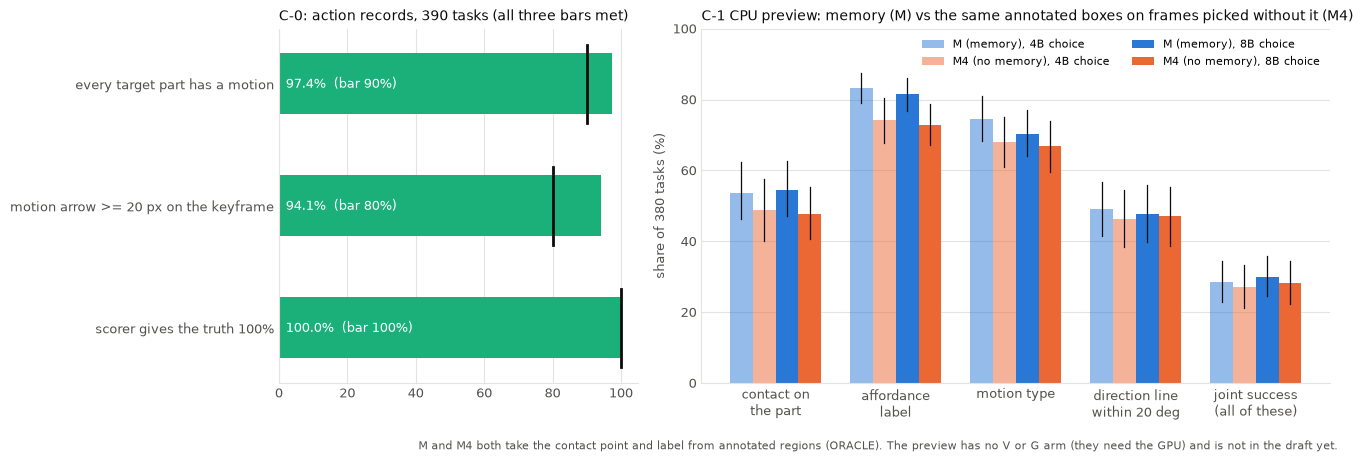

C-1 preview (4B choice), rotating tasks: 159; M's annotated label is a pull type on 84, and 73 of those get the axis class wrong
C-0: 129 of 160 annotated rotations have an axis up and down the image (vertical)


In [16]:
c0 = get("c0", "criteria")
print(f"C-0: every target part has a motion {100 * c0['motions_for_every_part']['share']:.1f}% (bar 90%); arrow >= 20 px "
      f"{100 * c0['arrow_at_least_20px']['share']:.1f}% (bar 80%); scorer gives the truth 100%: {c0['scorer_gives_truth_100']['holds']} "
      f"-> {get('c0', 'verdict')}")
fields = {"contact": "接触点在部件上", "label": "affordance 标签对", "type": "运动类型对", "line_ok": "方向直线误差 ≤ 20 度",
          "axis_class": "转轴类别（转动的任务）", "vertical_axis_class": "底线：转轴总是答竖直", "joint": "联合成功"}
rows = []
for model, name in (("4B", "c1_4b"), ("8B", "c1_8b")):
    for arm in ("M", "M4"):
        row = {"组": f"{arm}（{model} 的选择）"}
        row.update({label: rate(get(name, "arms", arm, field)) for field, label in fields.items()})
        rows.append(row)
display(pd.DataFrame(rows).set_index("组"))
for model, name in (("4B", "c1_4b"), ("8B", "c1_8b")):
    reading = get(name, "readings")
    print(f"M minus M4, joint success ({model}): {diff(reading['memory_value_M_minus_M4_joint'])} points -> {reading['memory_value_verdict']}; "
          f"scorer check on the truth (O): {get(name, 'scorer_check', 'holds')}")
show(c_figure(D["c0"], D["c1_4b"], D["c1_8b"]))
# why "always vertical" beats M on the axis class: rotating tasks whose annotated label is a pull type (the rule makes them translations)
PULL = {"hook_pull", "pinch_pull"}
rotating = pulled = pulled_axis_wrong = 0
for scene_file in sorted((RUNS / "mem_c1/preview/4b").glob("[0-9]*.json")):
    scene = json.loads(scene_file.read_text())
    for truth, memory in zip(scene["arms"]["O"], scene["arms"]["M"]):
        if (truth.get("prediction") or {}).get("type") != "rot":
            continue
        rotating += 1
        if (memory.get("prediction") or {}).get("label") in PULL:
            pulled += 1
            pulled_axis_wrong += not (memory.get("score") or {}).get("axis_class")
axes = get("c0", "sign_diagnostics", "axis_classes")
D["c1_rotations"] = {"rotating": rotating, "pulled": pulled, "pulled_axis_wrong": pulled_axis_wrong,
                     "vertical_in_c0": axes["up and down the image"], "rotations_in_c0": sum(axes.values())}
print(f"C-1 preview (4B choice), rotating tasks: {rotating}; M's annotated label is a pull type on {pulled}, "
      f"and {pulled_axis_wrong} of those get the axis class wrong")
print(f"C-0: {axes['up and down the image']} of {sum(axes.values())} annotated rotations have an axis up and down the image (vertical)")

**按规则的判定：**
- **C-0 通过：** 97.4% 和 94.1% 都过了门槛，打分程序给真值 100%、给故意答错的 0%。但**符号约定没通过核对**："按"类部件按计划的读法几乎都变成往外移动（80 个里只有 4 个对）。所以按事先的规则，C-1 只对方向的**直线**打分（不分推还是拉）。另一种读法（`motion_dir` 就是部件移动的方向）有 95.9% 对得上；你在第 9 轮回答"3 b"：主结果只比直线，"推还是拉"按这种读法另报，标明是计划之外加的。
- **C-1 的主判定（M 减 V）还没有。** 4B 在场景 421254（19 个任务）上的试跑（11-16，§25.5）：O 100%，M 37%、M4 32%、M' 47%，但 V、G、V'、G' 的联合成功都是 0（带撇号的是 §25.5 的诊断组：都改用目标部件像素最多的那一帧，把"挑帧"和"答动作"分开）。原因在答案格式，不在模型能力：模型在 `label` 里写部件名（"handle"、"knob"），读不出九类标签之一；`arrow_end` 照抄接触点，箭头长度为 0，没有方向。G 用的是 V 的接触点和标签，所以跟着是 0。全部运行之前只改了 V 的提问（账本 D-11）：逐条列出九个标签的原样字符串，要求 `label` 必须是其中之一；`arrow_end` 改为离接触点至少 50 个单位、表示部件往哪边动；附一个格式完整的例子；答案缓存换成 c1-v2。打分程序、读取规则、G、M、M4 和所有门槛都没改。试跑重新排队，先在 421254 上再跑，再跑其余场景。这和第 7 轮试跑后改提示词（D-7）是同一类修改：在全部运行之前、为了对普通模型公平。
- **预览里的 M 减 M4（只作描述）：** 4B +1.3 [−3.5, +6.0]，8B +1.8 [−1.9, +5.4]，按 D-10 的读法都是"接近"：给同样的标注框，记忆挑画面在 C 上也几乎没有多给什么。和第 3.4 节的 c4 是同一个结论。

**这意味着什么，和一个没解释的现象：**
- C 现在能说的只是"在标注的部件图下，记忆能给出接触点和类别"；它离"能直接拿去做"还远：联合成功只有约 28% 到 30%（ORACLE）。
- **"总是答竖直"的底线比 M 高，原因是事先写定的规则本身的一个弱点。** 预览里转轴类别 M 只对 34% 到 36%（M4 更低），而"总是答竖直"的底线是 82.4%。§25.5 的几何规则（G 和 M 都用）按标签定运动类型：拉类标签（hook_pull、pinch_pull）一律当平移。可是标注里有不少门的把手标成 hook_pull 或 pinch_pull，而门实际上是转动的；这些任务的运动类型就判错，转轴类别也跟着错。下面从预览的逐任务记录数出来：159 个转动的任务里，M 用到的标注标签是拉类的有 84 个，其中 73 个转轴类别判错。另一方面，标注里的转动大多是竖直的轴（C-0：160 个转动里 129 个），所以"总是答竖直"天然很高。这是计划里写定的规则的已知弱点，照计划记录，不在看结果之后改规则；C-1 的报告里要和这条底线并排写。

## 4. 主张怎么变的

| 时间 | 那时的主张 | 为什么改 | 依据 |
| --- | --- | --- | --- |
| 11-10，第 1 轮 | 定位"部件级 4D 功能记忆"；以 H3（交互帮助构建记忆）、H2（事件结构帮助检索）为主 | 记忆方向独立成仓库，第一次定位 | 讨论稿 §11；你的方向原话（第 0 节） |
| 11-12，第 6 轮 | **功能记忆：** 环境记忆按"能对什么做什么、做过什么"来组织和写入，而不是按帧、按物体或按融合的几何。三个可否证的预测：A（写在哪里）、B（事件）、C（代价） | 第 5 轮的评估：当时的原型"还不是一项研究贡献"，没有可以被否证的中心主张 | §20.2、§20.5、§21.1 |
| 11-13，第 7 轮 | 同上，G1 按收窄后的含义通过：按功能建索引在 ORACLE 下有效；"写在哪里"本身约 7 个百分点 | 阶段 1 的规则都满足，但 §23 把增益拆开后，大半是"哪些关键帧有部件"这一帧级信息 | §22.2、§23.3；第 3.1 节 |
| 11-13，第 8 轮 | **你描述的论文（CA 到 CD）：** CA 新的 affordance map 构建方法；CB 按功能搜索，不同于传统视觉语言模型读视频；CC 比它更快更准；CD 在动作类问题上格外强 | 你在聊天里写出了希望论文最后能说的贡献（"使用较为新颖的affordance map的方法，通过一个与传统vlm模型不同的搜索方式……"）；第 8 轮复述后你确认"1 对；2 同意" | `helm/rounds/R8.md`；账本 R8 |
| 11-13，第 9 轮 | **方案乙：** 重心放在按功能搜索、动作类问题和代价曲线；构建方法用现成的，算不算贡献等检查再定（DF-4）；C 是论文的一节，B 并行、不进主表 | 调研：CA 是四项里最弱的（FunGraph 已在画面上训练带动作类别的部件检测器；第 3 轮审稿找到的 Functional-SLAM 在线建部件、跨画面合并）；对照 c：P4 的领先来自标注框；CD-A 还没有证据（p = 0.16）。乙收回了你第 8 轮问题 2 的"同意"，所以交你定，你选了"乙" | `helm/rounds/R9.md` 第 4、5 节；§24.5 |
| 11-13，第 10 轮 | **"检索变难时"的部件级功能记忆**（第 0 节的原文），三个预测：1 现成工具建的部件图够用；2 检索越难、功能索引的优势越大；3 写入算进去仍然划算。动作方向改由 C 体现（先在 2b 里再试一次）；B 先停 | c4 接近 P4（4B +4.4、8B +6.7）；动作键只多 +0.8（真值 +3.8）；B-1 没过。评估写明：预测 2 是**看到 c4 之后才形成的假设**，讨论稿 §5 的 H1 到 H4 里没有对应，需要你认可；你回答"1 同意" | `helm/assessments/2026-11-13.md` 第 1、4 节；§24.8、§24.10、§25.4 |
| 11-13 到 11-15，2b 之后 | 主张没改，但它的第一步在检索这一步没过（差一直在、不随难度变大）。你选了"c+a"：先做现成工具的检查，同时测端到端；P-4 先不批 | 2b 的斜率区间包含 0 | §26；账本 2026-11-15 |

**一句话：** 主张从"按功能组织记忆"（宽）收窄到"按功能建索引在 ORACLE 下有效"，再被你扩成一篇有方法贡献的论文（CA 到 CD），又因为调研和对照收回到"现成构建器 + 按功能搜索"（乙），最后因为 c4 收窄到"只有检索变难时记忆才起作用"。每一步收窄都是事先写定的规则读出来的，不是看了结果改规则；唯一的例外是预测 2 本身，它是看到 c4 之后才提出的假设，评估里明说了。

## 5. 调研地图

**读到哪一层：** 摘要 < 方法部分 < 表格 < 全文。下表没有一篇是通读全文的；"掌舵代理核对过"指掌舵代理自己对照过原文的那一层，其余是调研代理或审稿代理读到的。完整记录在 `helm/evidence/` 的 7 个文件里。

| 方向 | 最近的工作（读到哪一层） | 已经被做了什么 | 留给本项目的空间 |
| --- | --- | --- | --- |
| 给模型看编号候选框 | Set-of-Mark、MOKA（方法）；AffordBot，NeurIPS 2025（方法，要点云和渲染视角）；ThinkAfford，2026-08（方法） | "编号框让模型找到部件"这个机制 | 不能声称；"有部件框从约 28% 到约 50%"只当基线结果报告 |
| 视觉语言模型的瓶颈在哪 | "Part Grounding, Not Action Knowledge"，2026-09（掌舵代理核对过摘要） | 瓶颈是找到部件，不是知道动作 | 和我们的结果一致（第 3.4、3.6 节）；也解释了动作键为什么没用 |
| 从视频建部件级功能图 | FunGraph，IROS 2025（表格：用投影的标注训练二维部件检测器，mAP50 26.7；零样本 GroundingDINO 0.7）；Functional-SLAM，CoRL 2026（掌舵代理核对过摘要和引言；在线建部件节点、跨画面合并、不存融合地图）；HHOpenFunGraph（表格，部件召回 70.1%，指标定义没核实）；OpenFunGraph（表格）；OP3DSG，ECCV 2026（方法） | "不需要问题、部件级、带动作类型"的部件图，在点云上和带位姿的画面上都有人做了 | 构建方法是四项里最弱的；算不算贡献等阶段 2a（DF-4） |
| SceneFun3D 上每个问题重新处理场景 | UniFunc3D，NeurIPS 2026（表格：读视频画面，AP25 44.04，每题 53 到 99 秒，8 张 H100）；Fun3DU（AP25 33.3，别人复现 23.4 和 12.56）；T-FunS3D（表格：建一次约 592 秒、之后每题 78 秒，AP25 34.5）；AFFORDMEM（AP25 41.66；它的表里"用问题文字直接提示 SAM 3"AP25 30.45，掌舵代理没核实）；TASA（每题 37.6 秒） | 高精度，但每题几十秒；"写一次、问很多次"T-FunS3D 已有（用点云） | 同一协议下并排（DF-5，阶段 3）；写入算全的代价曲线（预测 3） |
| 写一次的记忆（物体级） | 3D-Mem，CVPR 2025（表格）；VL-KnG（表格，约 10 个问题回本）；Video-EMem，2026-10（掌舵代理核对过摘要）；SpatialMem（arXiv 2601.14895，表格：物体级第一人称记忆，相同画面预算下检索证据画面，不到部件） | 物体级的"写一次、问很多次"和它的回本点 | 部件级；写入算全 |
| 记忆的优势随难度变大 | CapMem、MERIT，2026（表格：通用视频问答里，记忆的优势随视频变长而变大）；OpenGround / OpenTarget，2025-12（表格：同类部件很多时，给了真值候选的定位模型也会崩） | 通用视频问答里有；部件级没有找到（检索不是穷尽的） | 预测 2 的空间；OpenTarget（7,724 个问题、平均每个场景 8.35 个同类部件，调研代理读到，掌舵代理没核实）可能适合测"相似部件多" |
| 问"做过什么" | AMEGO，ECCV 2024（方法）；EgoSG，2026（摘要） | 物体和设施一级已有 | 部件级没有，但 B 没有不用标注的写入方法；B 已停 |
| 能直接拿去做的回答 | AffordBot（表格）；AFUN，2026-06（摘要）；SceneFun3D 的任务 3 | 每个问题给出动作类型、方向或接触点 | 从写一次的记忆里给出；它最接近兄弟项目，只对着标注打分 |

**调研代理归纳的"空白格"**（推断，来自 `field_2026-11-13_landscape_affordance_construction.md`）：同时满足"只用视频、不用扫描点云；部件级；封闭的动作词表；跨画面一个部件一条；写入便宜；以找全场景里所有部件为目标；按检索来评测"的工作没有找到。但 Functional-SLAM 已覆盖其中大部分，所以剩下的主要是"把部件图当回答问题的索引"和"写一次、问很多次的代价"。

**领域里的数字不能直接和我们的比：** 别人报告的是三维掩码的 AP（官方指标）；我们用的是二维的"框中心落在部件上"，没有已发表的对应（审稿 V-65）。要并排，得把框投到三维、按官方指标打分（DF-5）。

## 6. Research scope 大局

**围栏（章程第 3 节；P-4 没批，所以仍是第 9 轮改过的版本）**

| | 包括什么 | 本周的变化 |
| --- | --- | --- |
| 围栏内 | 室内环境的部件级功能记忆：从视频写入一次，按查询读取；在公开基准上与静态记忆、逐查询重新处理场景的方法对照；用现成的构建器建 affordance map（不训练）；能直接拿去做的回答，只对着标注打分 | 第 9 轮加了"用现成构建器""能直接拿去做的回答" |
| 边缘 | 人形展示（补充材料）；训练写入器或检测器（到 G2）；时间维度的事件记忆（B-0、B-1 已做；之后每一步另问）；新的构建方法作为论文贡献（等 DF-4） | 第 9 轮加了"检测器"和"新的构建方法作为论文贡献"；事件记忆：第 10 轮你选 B 先停（P-4 第 4 处会把这一点写进章程，暂缓） |
| 围栏外 | 训练 VLA 或机器人控制；自己录制数据；把稠密重建当作方法的输入 | 不变 |

**半径：** medium，限于三件事：用现成构建器替换环节 4 的标注；环节 10（检索）按动作类型检索；C 的检查和 B-0、B-1。主张本身的替代设计按 narrow，要改主张先问你。**推断：** "按动作类型检索"已经不再是主张，P-4 第 3 处会把半径改成"2a、2b、C"，暂缓。

**预测：活着的、没过的、没测的**

| 预测 | 来自 | 状态 | 依据 |
| --- | --- | --- | --- |
| A（写在哪里） | 第 6 轮，§20.5 | 在 ORACLE 下成立，含义收窄（G1） | §22–23 |
| B（事件好于只有时间戳） | 第 6 轮 | B-1 没过，B 先停 | §25.4 |
| C（写一次、查多次更省） | 第 6 轮 | 没测（只量了读） | §22.3、§24.8 |
| CD-A（动作类问题格外强） | 第 8 轮 | 没有证据，不再当主张 | §24.5、§24.10、§26 |
| 预测 1（现成工具的部件图够用） | 第 10 轮 | 没测；示例图你看过（11-16），只用 SAM 3，全部运行已排到前面 | §24.9 |
| 预测 2（检索越难优势越大） | 第 10 轮 | 检索这一步没过；端到端排队中 | §26、§26.2 |
| 预测 3（写入算进去仍划算） | 第 10 轮 | 没测；划算点暂定 15 个问题 | 评估第 4 节 |

**停止清单**（评估第 13 节建议、你在第 10 轮选定的）：按动作类型检索当作主张；B 和标题里的"4D"（"4D"到 G3 定）；为了归因再在标注部件图上加对照（2b 的上限检查除外）。更早停下的（§20.8）：打磨单个场景的示例、改进人形、给流程再加环节。

**一篇论文今天能说什么，还缺什么**（推断，依据评估第 1、3、9 节）
- **今天能写的一句话：** 在标注的部件图下、30 个 SceneFun3D 场景上，给视觉语言模型看编号的部件框，选对部件从约 28% 升到约 50%（4B、8B 一致）；单个房间里，记忆挑画面在此之上只多 4 到 7 个百分点。这是一个基线结果，机制别人做过，所以单独撑不起一篇论文。
- **还缺：** 一个不用标注的结果（预测 1，阶段 2a）；检索变难时端到端的优势（预测 2，先是 2b 端到端，最好再在现成基准上，例如 OpenTarget 或 HD-EPIC，下载要你批）；写入算全的代价曲线（预测 3）；同一协议下的已有系统（UniFunc3D 便宜版、直接提示 SAM 3；用扫描打分另问你，DF-5）；报告全部 445 个任务（看不到的算错，审稿 V-69）。
- **评估第 10 节的话：** 如果预测 2 不成立，剩下的是"部件图当记忆 + 代价"，也就是审稿人说的"检测器加编号框"，**很可能过不了章程里"想法本身要立得住、不是插件"这一条**。那时不是换个说法继续，而是到 G2 由你决定。

**会议**
- NeurIPS 2027 的日程和审稿指南还没公布（11-13 查过）。2026 年对"由应用驱动"类论文的指南要求：用例真实而有意义；任务、方法和指标贴合用例；和常用的非机器学习做法及基线比；分析为什么有效（评估第 12 节，读到 2026 年的指南）。
- 本项目的用例是你在第 7 轮选的：家里的使用指导、无障碍与远程协助为主，家用机器人作为补充说明（"我希望优先一和三，二作为补充说明"）。
- ICCV 2027 是否先投、WACV Applications 是否加入，都到 G2 定。CVPR 2027 已经赶不上（摘要登记 11-10 截止，§20.7）。

**掌舵代理的看法**（原文照录）

> 这一周把阶段 1 和它的补充对照都做完了，结论比一周前清楚、也比一周前保守。清楚的是：给视觉语言模型看部件的编号框，它选对要操作的部件的比例从约 28% 升到约 50%（标注的部件图，4B 和 8B 一致），这是这一周最可靠的结果。保守的是：在单个房间里，记忆本身（挑画面、按动作类型检索）在这之上只多几个百分点；第 10 轮把主张改成"检索变难时功能记忆才起作用"，但它的第一步（把多个场景混在一起检索）在检索这一步没有通过：功能索引一直比语义检索多 12 到 18 个百分点，但这个差不随难度变大。所以项目现在站在一个岔口：一是正在排队的"端到端"版本（混合之后模型最后能不能选对部件）和现成工具建图的检查，这两个结果决定主张还能不能站住；二是如果站不住，到关口 G2 由项目负责人在"做新的构建方法、换会议、重新想"之间选。下周最要紧的是拿到这两个结果，而不是再加新的标注对照。

**把这个看法展开**（依据评估第 10、11 节和 §24.9、§26.2 的读法，不是新的建议）：

| 两个结果 | 事先写定的读法 | 之后 |
| --- | --- | --- |
| 2b 端到端（§26.2） | 功能索引减语义（选对部件）对 log2 K 的斜率区间下沿大于 0，且 K = 16 时差至少 5 个点：端到端支持预测 2 | 支持：预测 2 还活着，下一步是现成基准（阶段 3，要你批下载）。不支持：按评估第 10 节到 G2 |
| 阶段 2a（§24.9） | 工具版 P4 减 c3、工具版 P4 减"直接提示 SAM 3"，有一个区间下沿不大于 0 就停下讨论；标注版 P4 减工具版 P4 的区间上沿低于 10 个点：现成工具够用 | 够用：支持"构建方法暂不算贡献"（DF-4）。差很多而且召回随写入预算明显上升：构建方法有事可做，交你重新考虑 DF-4 |
| G2 的三条路 | 做新的构建方法（在边缘，要训练）；换会议（WACV Applications 候选）；停下来重新想 | 都由你定 |

## 7. 进行中和下周

**队列**（GPU 作业只走队列；账本 2026-11-16）

| 作业 | 位置 | 状态（截至 2026-11-16 傍晚） |
| --- | --- | --- |
| 问题 2 检查的示例图：SAM 3、Qwen3-VL-8B 当检测器（3 个场景、6 张关键帧） | 11-16 按你的"b"插到前面 | 跑完，给你看过（下图）；你定"a，插到前面"，流程关口算通过 |
| 阶段 2a 全部运行：SAM 3 的部件图，以及用任务文字直接提示 SAM 3 的框；之后 8B 读图（GPU 上限 7 小时） | 11-16 按"a，插到前面"排到前面 | SAM 3 已开始写出结果文件（本 notebook 不读）；Qwen3-VL-8B 的检测不做 |
| C-1 试跑（场景 421254，4B） | 11-16 插到前面 | 跑过一次：V、G、V'、G' 因答案格式都是 0；改了 V 的提问（D-11，缓存 c1-v2），重新排队 |
| 2b 端到端（`200_mem_pooled_reading_*`，8B，约 2,340 次调用） | 排在你的作业后面 | 排队中；11-16 网络恢复时估计约 22 小时后轮到 |

**11-16 的经过：** 服务器网络断了一阵，恢复后队列里有 793 个作业，我们的都排在你的作业后面。你回答"b"：两个小作业（示例图、C-1 试跑）插到前面，2b 的端到端版本仍排在后面。示例图跑完后给你看了，你选了"a，插到前面"（选项是：(a) 只用 SAM 3 全部跑，Qwen 这次不做；(b) 先改 Qwen 的提示词再看；(c) 两个都跑）。§24.9 的读法照旧，"以哪个工具为准"一条因为只剩一个工具而不再需要。

**问题 2 检查的示例图**（`runs/mem_phase1/tool_maps/gate.png`，不进 git；这里缩小显示）：每一行是一个场景的两张关键帧，每张关键帧左边是 SAM 3（用 8 个部件名提示，橙色框），右边是 Qwen3-VL-8B（要它用 JSON 框出这 8 类部件，蓝色框）。实线框的中心落在标注部件上（放宽 8 个像素），虚线框没有；白色轮廓是标注的部件，只用来判断，没有给工具。图里每格标题写了框的个数和落在部件上的个数；按"落在部件上的 / 框的个数"写：SAM 3 在 6 张关键帧上是 16/16、19/19、5/6、4/6、4/4、4/4；Qwen3-VL-8B 是 0/0、9/19、0/0、0/1、2/5、0/0（3 张回答的是空列表，记录里写作 4 张，见第 8 节）。

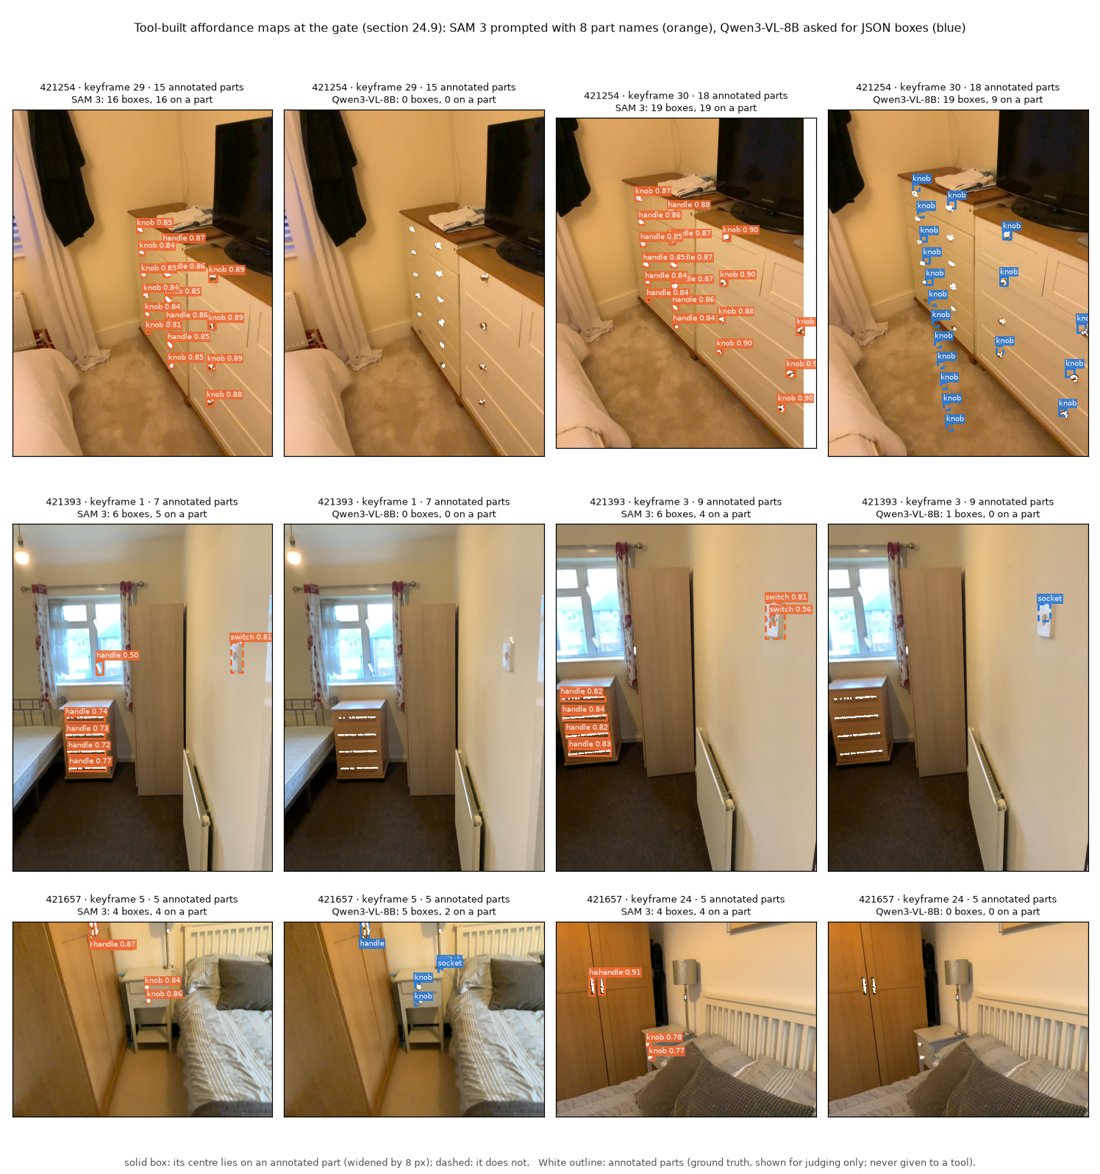

In [17]:
from io import BytesIO

from IPython.display import Image as ShowImage
from PIL import Image

gate_file = RUNS / "mem_phase1/tool_maps/gate.png"
if not gate_file.is_file():
    raise FileNotFoundError("runs/mem_phase1/tool_maps/gate.png is missing: run scripts/draw_tool_maps.py")
gate = Image.open(gate_file).convert("RGB")
gate = gate.resize((1100, round(gate.height * 1100 / gate.width)))
buffer = BytesIO()
gate.save(buffer, format="JPEG", quality=85)
display(ShowImage(data=buffer.getvalue(), format="jpeg"))

**等你定的**
1. **示例图：** 已定（11-16，"a，插到前面"）；这一条不再等你。
2. **P-4：** 暂缓；等 2b 端到端和 2a 的结果再改写。
3. **G2 的路（如果预测 2 端到端也不支持）：** 新的构建方法、换会议、重新想（第 6 节）。
4. **推迟的决定还在：** DF-3（阶段 2 的其余部分）；DF-4（构建方法算不算贡献，等 2a）；DF-5（和 UniFunc3D 并排，阶段 3，用扫描打分另问）；"4D"是否留在标题（G3）。
5. **流程上的一件事：** 账本记着距上次 distill（把做法沉淀成习惯）已经 5 轮，按规则该提议一次；还没提。

**下周按已批的计划要做的**（掌舵代理的下一步，账本开头）
- 2a：SAM 3 跑完后算召回和覆盖（CPU），再用 8B 读图（工具版 P4、工具版 c4、直接提示 SAM 3）；按 §24.9 的读法记录。Qwen3-VL-8B 的检测不做。
- C-1：用新的提问（c1-v2）重新试跑、检查，然后全部运行（4B；之后用 8B 再跑一遍 V），按 §25.5 记录。
- 2b 端到端轮到后跑完，按 §26.2 的读法记录。
- 每一项的读法都在跑之前写定；结果出来后各写一条记录，需要决定的集中到一份文档。

## 8. 风险和诚实说明

**ORACLE**
- 用了标注部件图的组都是上限：阶段 1 的 P4（检索和端到端）、对照里的 P4 和 c4、R7-B、动作键、2b、C-1 的 M 和 M4。阶段 1 的 P2、P3 和 b 的区域个数、大小按 P4 匹配，间接用到了标注。
- c2、c2' 自己画框，但它们的画面是记忆挑的，而记忆挑画面用到了标注的关键帧标记。
- 不用标注的组：c1、c1'、c3、c+，以及 B-1。它们不是上限，但只是 4B、8B 加我们定的读法，不是这个领域最强的对手。

**设定上的局限**
- **单个房间：** SceneFun3D 每个场景一个房间、40 张关键帧；评估的看法是，这是"语义检索已经够用"的容易情形（推断，看到 c4 之后才形成）。2b 混进来的是别的房间，比"同一段长视频里的相似部件"容易。
- **任务被挑过：** 390 个任务是按"我们的关键帧里看得到"选的（445 个里的 390 个）；审稿要求以后报告全部任务、看不到的算错（V-69）。
- **任务的写法：** SceneFun3D 的每个任务都点明了部件和动作，只问标注过的功能部件，对 affordance 的写法有利（§21.9）。
- **指标：** 二维的"框中心落在部件上"，没有已发表的对应；没有按官方的三维指标比过（V-65）。
- **模型：** 视觉语言模型只用了 Qwen3-VL 一家（4B、8B）；时间只算模型调用，8B 比 4B 快的原因没查。

**看到结果之后才加的东西**（每一处在记录里都写明了）
- §23 的归因检查和常数扫描：审稿之后加的（D-4），计划在算之前提交。
- R7-B 的更严的重算：审稿之后加的，规则在算之前写定。
- B-0 的坐标修补：按事先的规则先判为数据问题，修补是看到结果之后做的；你接受后才记为通过。
- 2b 的端到端版本：检索这一步没过之后才加的（§26.2 开头写明）。
- 预测 2 本身：看到 c4 之后才形成的假设（评估第 1 节）。
- C-1 的"推还是拉"：计划之外另报（你的"3 b"）。
- 在跑之前改过的读法：§24.9 读法 2（D-9，因为按原文"召回随预算上升"一定成立）；§24.9 停的规则（第 10 轮问题 3"b"）；C-1 加 M4（D-10）；对照的提示词和回答长度（D-7，试跑后、其余场景之前）。

**改正过的流程失误**
- 结果文件和 notebook 曾打印"G1: passed"，而过关由你决定；改成"规则的类别……过关由项目负责人决定"（V-14）。
- 第 7 轮简报开头说"改写后又审了一遍"时，那一轮还没审完；补上了各轮结论（V-31）。
- 第 9 轮简报初稿把标注框的功劳算成了记忆的（阻断项 V-38），改写后才交给你。
- 调研代理漏掉了 Functional-SLAM，第 3 轮审稿才找到；建议因此从丙改成乙。
- 讨论稿 §20.5 说 UniFunc3D 需要点云，实际输入是视频画面；加了带日期的更正（V-72）。
- "对误检不敏感"说得太宽，收窄为"检索这一步、误检和部件一样大时"（V-73）。
- 账本开头和章程 G1 一行曾经过时（V-71）；账本开头已每次提交更新，章程 G1 一行要随 P-4 一起改。
- 账本里引你的原话时把弯引号写成了直引号，加了更正（账本 R8）。
- 审稿循环两次到了章程允许的 3 轮上限，最后一轮的意见照改、没有再审（第 7 轮的贡献图、第 9 轮简报）；第 10 轮评估的审稿人没看到 §24.8、§24.10 的记录。

**本 notebook 自己的说明**
- C-1 的 CPU 预览（第 3.9 节）是服务器上已有的结果文件，讨论稿里还没有记录，也没审过；这里只作描述。
- 第 7 节显示了示例图；C-1 试跑的数字照 §25.5 的记录引用，没从文件读（重新试跑会覆盖那个文件）；11-16 晚上开始写出的 SAM 3 全部运行的结果，本 notebook 没读。
- **一处和记录对不上的地方：** 账本和 §24.9 写 Qwen3-VL-8B "有 4 张直接回答空列表"。按服务器上的答案文件，6 张里 3 张回答的是空列表；另一张只给了 1 个框、不在部件上，所以没有一个框落在部件上的是 4 张。第 7 节的说法按文件写。
- "总是答竖直"那一条（第 3.9 节）：第一版写成"原因没查"，现在按 §25.5 的规则解释清楚了，是事先写定的规则的弱点。
- 第 1–6 轮没有你的逐字回答（接入 research-helm 之前），时间线里写的是讨论稿记下的决定。

## 9. 附录

### A. 数字和出处

下表每一行是正文里引用的一个数字：取自哪个结果文件的哪一项，运行时从文件重新算一遍，和正文写的对一下（"核对"一列）。格式：比例写成"值 [区间]"，差写成"个百分点 [区间]"。

In [18]:
SOURCES = [  # what the text quotes, the value as written, file, path in the file, format, section
    ("阶段 1：P4 第一个关键帧对", "66.2% [60.0, 73.3]", "phase1", ("first_keyframe_right", "P4"), "rate", "§22.3"),
    ("阶段 1：P3 第一个关键帧对", "47.3% [39.5, 55.9]", "phase1", ("first_keyframe_right", "P3"), "rate", "§22.3"),
    ("阶段 1：P0 第一个关键帧对", "45.6% [37.4, 54.5]", "phase1", ("first_keyframe_right", "P0"), "rate", "§22.3"),
    ("阶段 1：P2 第一个关键帧对", "38.5% [32.0, 45.6]", "phase1", ("first_keyframe_right", "P2"), "rate", "§22.3"),
    ("阶段 1：P4 减 P3", "+18.8 [+12.9, +24.9]", "phase1", ("first_keyframe_right", "P4 minus P3"), "diff", "§22.2"),
    ("阶段 1：端到端 P4（4B）", "53.6% [46.2, 61.6]", "phase1", ("reading", "P4 affordance regions"), "rate", "§22.2"),
    ("阶段 1：端到端 P3（4B）", "10.3% [7.5, 13.4]", "phase1", ("reading", "P3 generic regions"), "rate", "§22.2"),
    ("§23：只用比特减 P0", "+9.0 [+6.1, +12.5]", "diag", ("differences", "whole keyframes + which keyframes hold an affordance region minus P0 whole keyframes"), "diff", "§23.3"),
    ("§23：只用 token 减 P0", "+17.4 [+11.7, +23.7]", "diag", ("differences", "P4, no penalty for keyframes without a token minus P0 whole keyframes"), "diff", "§23.3"),
    ("§23：P4 减 P0", "+20.5 [+14.4, +26.9]", "diag", ("differences", "P4 affordance regions minus P0 whole keyframes"), "diff", "§22.4"),
    ("§23：同关键帧 P4 减 P3", "+7.0 [+2.8, +11.3]", "diag", ("differences", "P4 affordance regions minus P3 in the keyframes of P4"), "diff", "§23.3"),
    ("§23：框里有正确部件，P4", "83.6% [78.2, 89.3]", "diag", ("a_shown_box_is_on_the_target", "P4 affordance regions"), "rate", "§23.3"),
    ("§23：框里有正确部件，P3", "20.0% [13.8, 27.9]", "diag", ("a_shown_box_is_on_the_target", "P3 generic regions"), "rate", "§23.3"),
    ("随机挑一张关键帧", "9.2%", "diag", ("chance", "a random keyframe"), "pct", "§23.3"),
    ("对照 c：P4（4B）", "53.1% [45.5, 61.7]", "c4b", ("arms", "p4n", "right_part"), "rate", "§24.5"),
    ("对照 c：c3（4B）", "28.5% [23.5, 34.0]", "c4b", ("arms", "c3", "right_part"), "rate", "§24.5"),
    ("对照 c：c2（4B）", "17.2% [13.4, 21.3]", "c4b", ("arms", "c2", "right_part"), "rate", "§24.5"),
    ("对照 c：c1（4B）", "15.1% [11.7, 19.0]", "c4b", ("arms", "c1", "right_part"), "rate", "§24.5"),
    ("对照 c：P4 减 c3（4B）", "+24.6 [+19.2, +31.5]", "c4b", ("against_p4", "c3"), "diff", "§24.5"),
    ("对照 c：P4 减 c1（4B）", "+37.9 [+31.2, +45.4]", "c4b", ("against_p4", "c1"), "diff", "§24.5"),
    ("对照 c：c2 减 c1（4B）", "+2.1 [−1.1, +5.4]", "c4b", ("choosing_keyframes",), "diff", "§24.5"),
    ("c3 的 40 帧看得到目标", "98.2%", "ceiling", ("share",), "pct", "§24.5"),
    ("第二批：c+（4B）", "26.4% [21.9, 31.7]", "c4b", ("arms", "cplus", "right_part"), "rate", "§24.7"),
    ("第二批：d（4B）", "14.1% [11.4, 17.1]", "c4b", ("arms", "d", "right_part"), "rate", "§24.7"),
    ("第二批：b（4B）", "11.4% [8.4, 15.0]", "c4b", ("arms", "b", "right_part"), "rate", "§24.7"),
    ("第二批：c+ 减 c3", "−2.1 [−6.6, +2.7]", "c4b", ("our_keyframes_vs_even_frames",), "diff", "§24.7"),
    ("a：全部网格档位", "53.6% [45.3, 62.2]", "a", ("arms", "a: every grid level"), "rate", "§24.7"),
    ("a：全部通用区域", "50.0% [44.1, 56.2]", "a", ("arms", "a: every generic region"), "rate", "§24.7"),
    ("c4（4B）", "48.7% [40.3, 57.5]", "c4b", ("arms", "c4", "right_part"), "rate", "§24.8"),
    ("P4 减 c4（4B）", "+4.4 [−0.9, +9.6]", "c4b", ("against_p4", "c4"), "diff", "§24.8"),
    ("c2' 减 c1'（4B）", "+3.6 [−0.9, +8.1]", "c4b", ("choosing_keyframes_same_reading",), "diff", "§24.8"),
    ("P4（8B）", "54.4% [47.1, 62.6]", "c8b", ("arms", "p4n", "right_part"), "rate", "§24.8"),
    ("c4（8B）", "47.7% [40.9, 55.3]", "c8b", ("arms", "c4", "right_part"), "rate", "§24.8"),
    ("c3（8B）", "27.7% [22.6, 33.0]", "c8b", ("arms", "c3", "right_part"), "rate", "§24.8"),
    ("P4 减 c4（8B）", "+6.7 [+1.8, +11.5]", "c8b", ("against_p4", "c4"), "diff", "§24.8"),
    ("c2' 减 c1'（8B）", "+3.6 [−0.8, +8.2]", "c8b", ("choosing_keyframes_same_reading",), "diff", "§24.8"),
    ("每题秒数：P4（8B）", "0.7", "c8b", ("arms", "p4n", "seconds_per_question"), "raw", "§24.8"),
    ("每题秒数：c3（8B）", "3.5", "c8b", ("arms", "c3", "seconds_per_question"), "raw", "§24.8"),
    ("每题秒数：P4（4B）", "1.2", "c4b", ("arms", "p4n", "seconds_per_question"), "raw", "§24.5"),
    ("每题秒数：c3（4B）", "5.7", "c4b", ("arms", "c3", "seconds_per_question"), "raw", "§24.5"),
    ("写入秒数（每个场景）", "24.3", "phase1", ("write_s_per_scene",), "one", "§22.3"),
    ("R7-B：留 100%、误检 0.5 倍，减 P3", "+15.2 [+10.4, +20.3]", "errors", ("grid", "random", "1", "0.5", "against_p3"), "diff", "§24.6"),
    ("R7-B：随机丢、留 25%、无误检", "52.2%", "errors", ("grid", "random", "0.25", "0", "rate"), "pct", "§24.6"),
    ("R7-B：先丢小的、留 25%、无误检", "47.2%", "errors", ("grid", "smallest_first", "0.25", "0", "rate"), "pct", "§24.6"),
    ("R7-B 更严的重算：随机丢、留 100%、误检 0.5 倍", "63.3%", "errors_centre", ("grid", "random", "1", "0.5", "rate"), "pct", "§24.6"),
    ("R7-B 更严的重算：先丢小的、留 100%、误检 0.5 倍", "62.3%", "errors_centre", ("grid", "smallest_first", "1", "0.5", "rate"), "pct", "§24.6"),
    ("动作类型的检验 p", "0.16", "by_action", ("heterogeneity_p4_minus_c3", "p_value"), "p", "§24.5"),
    ("动作短语减不加键", "+0.8 [−0.9, +2.4]", "key", ("against_no_key", "action phrase"), "diff", "§24.10"),
    ("真值动作类型减不加键", "+3.8 [+0.9, +7.5]", "key", ("against_no_key", "true type"), "diff", "§24.10"),
    ("动词减部件词", "+0.0 [−2.4, +2.2]", "key", ("verb_minus_part",), "diff", "§24.10"),
    ("2b：K = 1，功能索引减语义", "+13.8 [+8.7, +19.2]", "pooled", ("per_size", "1", "function index minus semantic (top3)"), "diff", "§26"),
    ("2b：K = 16，功能索引减语义", "+11.8 [+8.3, +15.7]", "pooled", ("per_size", "16", "function index minus semantic (top3)"), "diff", "§26"),
    ("2b：K = 16，语义的前 3 张有对的", "32.7%", "pooled", ("per_size", "16", "semantic", "top3", "rate"), "pct", "§26"),
    ("2b：斜率（每翻一倍）", "−0.7 [−2.2, +0.7]", "pooled", ("readings", "function index minus semantic", "slope_per_doubling"), "diff", "§26"),
    ("2b：动作键的斜率", "+0.1 [−0.7, +0.9]", "pooled", ("readings", "function index + action key minus function index", "slope_per_doubling"), "diff", "§26"),
    ("B-0：对上标注事件（原规则）", "16.9%", "b0", ("summary", "tied_share"), "pct", "§25.4"),
    ("B-0：规则答案对（原规则）", "11.1%", "b0", ("summary", "reproduced_share"), "pct", "§25.4"),
    ("B-0：对上标注事件（修补后）", "94.2%", "b0_swapped", ("summary", "tied_share"), "pct", "§25.4"),
    ("B-0：规则答案对（修补后）", "94.4%", "b0_swapped", ("summary", "reproduced_share"), "pct", "§25.4"),
    ("B-1：召回", "27.6%", "b1", ("summary", "recall"), "pct", "§25.4"),
    ("B-1：精度", "15.5%", "b1", ("summary", "precision"), "pct", "§25.4"),
    ("C-0：每个目标部件都有运动", "97.4%", "c0", ("criteria", "motions_for_every_part", "share"), "pct", "§25.4"),
    ("C-0：方向至少 20 像素", "94.1%", "c0", ("criteria", "arrow_at_least_20px", "share"), "pct", "§25.4"),
    ("C-1 预览：M 减 M4，联合成功（4B）", "+1.3 [−3.5, +6.0]", "c1_4b", ("readings", "memory_value_M_minus_M4_joint"), "diff", "预览"),
    ("C-1 预览：M 减 M4，联合成功（8B）", "+1.8 [−1.9, +5.4]", "c1_8b", ("readings", "memory_value_M_minus_M4_joint"), "diff", "预览"),
    ("C-1 预览：转轴总是答竖直的底线", "82.4%", "c1_4b", ("arms", "M", "vertical_axis_class", "rate"), "pct", "预览"),
    ("C-1 预览：转动的任务", "159", "c1_rotations", ("rotating",), "raw", "预览"),
    ("C-1 预览：其中标注标签是拉类的", "84", "c1_rotations", ("pulled",), "raw", "预览"),
    ("C-1 预览：其中转轴类别判错", "73", "c1_rotations", ("pulled_axis_wrong",), "raw", "预览"),
    ("C-0：转动里竖直的轴", "129", "c1_rotations", ("vertical_in_c0",), "raw", "§25.4"),
    ("C-0：标注的转动", "160", "c1_rotations", ("rotations_in_c0",), "raw", "§25.4"),
    ("B-1：手部跟踪的上限（推算）", "52%", "b1", ("summary",), "b1_ceiling", "§25.4"),
]
DERIVED = {"c1_rotations": "mem_c1/preview/4b/*.json 的逐任务记录和 mem_c0/summary.json（本节现算）"}
FORMATS = {"rate": rate, "diff": diff, "pct": lambda v: f"{100 * v:.1f}%", "raw": lambda v: f"{v}", "one": lambda v: f"{v:.1f}",
           "p": lambda v: f"{v:.2f}", "b1_ceiling": lambda v: f"{100 * v['palm_within_30cm_at_0'] * v['clock_check_palm_to_object']['n_at_0'] / v['truths']:.0f}%"}


def how(name, path, kind):
    if kind != "b1_ceiling":
        return "直接取值"
    v = get(name, *path)
    share, n, truths = v["palm_within_30cm_at_0"], v["clock_check_palm_to_object"]["n_at_0"], v["truths"]
    return (f"推算，文件里没有这个数：有手掌读数的 {n:,} 个标注时刻里，{100 * share:.2f}% 有一只手掌在物体 30 厘米以内；"
            f"除以全部 {truths:,} 个标注时刻：{100 * share:.2f}% × {n:,} ÷ {truths:,} = {100 * share * n / truths:.1f}%")
rows = []
for label, written, name, path, kind, section in SOURCES:
    computed = FORMATS[kind](get(name, *path)).replace("-", "−")
    rows.append({"正文里的说法": label, "正文写的": written, "从文件算出": computed, "核对": "一致" if computed == written else "不一致",
                 "文件（runs/ 下）": FILES.get(name, DERIVED.get(name)), "取的哪一项": " → ".join(path), "怎么得到": how(name, path, kind),
                 "讨论稿": section})
sources = pd.DataFrame(rows).set_index("正文里的说法")
display(sources)
mismatches = sources[sources["核对"] != "一致"]
print(f"{len(sources) - len(mismatches)} of {len(sources)} quoted numbers match their result files")
assert mismatches.empty, mismatches

,正文写的,从文件算出,核对,文件（runs/ 下）,取的哪一项,怎么得到,讨论稿
正文里的说法,,,,,,,
阶段 1：P4 第一个关键帧对,"66.2% [60.0, 73.3]","66.2% [60.0, 73.3]",一致,mem_phase1/summary.json,first_keyframe_right → P4,直接取值,§22.3
阶段 1：P3 第一个关键帧对,"47.3% [39.5, 55.9]","47.3% [39.5, 55.9]",一致,mem_phase1/summary.json,first_keyframe_right → P3,直接取值,§22.3
阶段 1：P0 第一个关键帧对,"45.6% [37.4, 54.5]","45.6% [37.4, 54.5]",一致,mem_phase1/summary.json,first_keyframe_right → P0,直接取值,§22.3
阶段 1：P2 第一个关键帧对,"38.5% [32.0, 45.6]","38.5% [32.0, 45.6]",一致,mem_phase1/summary.json,first_keyframe_right → P2,直接取值,§22.3
阶段 1：P4 减 P3,"+18.8 [+12.9, +24.9]","+18.8 [+12.9, +24.9]",一致,mem_phase1/summary.json,first_keyframe_right → P4 minus P3,直接取值,§22.2
阶段 1：端到端 P4（4B）,"53.6% [46.2, 61.6]","53.6% [46.2, 61.6]",一致,mem_phase1/summary.json,reading → P4 affordance regions,直接取值,§22.2
阶段 1：端到端 P3（4B）,"10.3% [7.5, 13.4]","10.3% [7.5, 13.4]",一致,mem_phase1/summary.json,reading → P3 generic regions,直接取值,§22.2
§23：只用比特减 P0,"+9.0 [+6.1, +12.5]","+9.0 [+6.1, +12.5]",一致,mem_phase1/diagnostics.json,differences → whole keyframes + which keyframes hold an affordance region minus P0 whole keyframes,直接取值,§23.3
§23：只用 token 减 P0,"+17.4 [+11.7, +23.7]","+17.4 [+11.7, +23.7]",一致,mem_phase1/diagnostics.json,"differences → P4, no penalty for keyframes without a token minus P0 whole keyframes",直接取值,§23.3


72 of 72 quoted numbers match their result files


**不在我们结果文件里的数字**（来自调研或文档，读到哪一层见第 5 节）：UniFunc3D AP25 44.04、每题 53 到 99 秒（8 张 H100）；Fun3DU AP25 33.3（别人复现 23.4、12.56）；T-FunS3D AP25 34.5、每题 78 秒、建一次约 592 秒；AFFORDMEM AP25 41.66；直接提示 SAM 3 的 AP25 30.45（掌舵代理没核实）；FunGraph 二维 mAP50 26.7、零样本 GroundingDINO 0.7；Functional-SLAM 前三召回约 16%（审稿人读到）；HHOpenFunGraph 部件召回 70.1%（指标定义没核实）；VL-KnG 约 10 个问题回本；OpenTarget 7,724 个问题、平均每个场景 8.35 个同类部件（掌舵代理没核实）。出处：`helm/rounds/R9.md` 第 4 节、`helm/evidence/`、评估第 5、6 节。队列的数字（793 个作业、每小时约 35 个、约 22 小时）来自账本 2026-11-16。示例图的框数来自 `gate.png` 每格的标题。C-1 试跑的数字（O 100%、M 37%、M4 32%、M' 47%，V、G、V'、G' 都是 0）来自 §25.5 的"试跑后的修改（2026-11-16）"，没从文件读，因为重新试跑会覆盖那个文件。

### B. 术语

| 术语 | 意思 |
| --- | --- |
| P0–P4 | 阶段 1 的五种写法，只有"token 写在哪里"不同：P0 只有整帧；P1 均匀网格；P2 随机位置；P3 通用区域（SAM 分出的，不知道哪里能操作）；P4 affordance 区域。对照里的"P4"（代码里叫 p4n）是同一份记忆加中性提示词和统一打分 |
| 第一个关键帧对 | 检索排在第 1 位的关键帧里有任务要找的部件；"前 3 张里有对的"同理 |
| 选对部件 | 模型选出或画出的框，中心落在目标部件上（部件向外放宽 8 个像素） |
| 比特（关键帧标记） | 每张关键帧一个"里面有没有可操作部件"的标记；在 ORACLE 下来自标注 |
| 编号框 | 在画面上给候选区域画框、标上编号，让模型回答编号 |
| c1、c2、c3、c4 | 第 7、9 轮的对照：c1 按语义挑 3 张、模型自己画框；c2 记忆挑 3 张、模型自己画框；c3 直接读 40 帧原视频；c4 按语义挑 3 张、给标注的编号框 |
| c1'、c2' | c1、c2 改用 c3 的读法：先挑一张，再在原分辨率上画框 |
| c+、a、b、d | 第二批对照：c+ 我们的 40 张关键帧、模型自己画框；a 全部通用区域或网格写进记忆（只看检索）；b 和 P4 一样多的通用区域（5 个种子）；d 得分最高的 40 个通用区域 |
| ORACLE | 用标注代替还没做出来的部件图；结果是上限 |
| 区间下沿 | 95% 置信区间的下端；"接近"的规则看它是否低于 5 个百分点 |
| 接近、说不清、落后于 P4 | §24.3 的读法：P4 减这一组的区间下沿低于 5 算接近；差本身大于 10 但下沿低于 5 算说不清；否则落后于 P4 |
| 4B、8B | Qwen3-VL-4B、Qwen3-VL-8B，现成的视觉语言模型，没有训练 |
| R7-B | 第 7 轮的选项 B：漏检和误检的模拟（§24.6） |
| 2a、2b | 阶段 2 的两部分：2a 现成工具建部件图（§24.9）；2b 把多个场景混在一起检索（§26），以及它的端到端版本（§26.2） |
| K | 2b 里混进一个记忆的场景数（目标场景加 K − 1 个别的） |
| B-0、B-1 | B（问"做过什么"）的头两步，HD-EPIC 厨房 P02（§25.1、§25.2） |
| C-0、C-1；V、G、M、M4、O；V'、G'、M' | C（能直接拿去做的回答）的头两步；C-1 的组：V 普通视觉语言模型、G 几何规则、M 我们的记忆、M4 同样的标注框但画面按语义挑、O 真值；带撇号的是诊断组，都改用目标部件像素最多的那一帧 |
| 预测 A、B、C | 第 6 轮主张的三个预测（§20.5）：写在哪里、事件、代价 |
| 预测 1、2、3 | 第 10 轮主张的三个预测（评估第 4 节） |
| CA、CB、CC、CD | 第 8 轮你描述的四项贡献：新构建方法、按功能搜索、更快更准、动作类更强（CD-A 点明动作、CD-B 做过什么、CD-C 能直接拿去做） |
| 甲、乙、丙 | 第 9 轮的三个方案：以构建方法为核心；按功能搜索、构建用现成的；两者结合 |
| 关口 | 理解、方向、流程、主张、G1（预算相同时 affordance 的 token 是否明显好于通用区域）、G2（主张是否成立、是否训练、投哪个会议）、G3（"4D"是否留在标题） |
| DF-1 到 DF-5 | 推迟的决定：DF-1 重建对照（已解决）；DF-2 关键帧选法（已解决）；DF-3 阶段 2 的其余部分；DF-4 构建方法算不算贡献；DF-5 和 UniFunc3D 并排 |
| D-1 到 D-11 | 掌舵代理在已批范围内自己定、你可以推翻的选择：D-1 LiDAR 为 0 时的尺度；D-2 填满窗口的区域的法线；D-3 全部重跑；D-4 规格外的检查；D-5 汇总的读法；D-6 加"直接读原视频"一组；D-7 提示词和回答长度；D-8 c+ 的 8B 先不跑等三件；D-9 读法 2 的修正；D-10 C-1 加 M4；D-11 C-1 试跑后改 V 的提问（c1-v2） |
| P-1 到 P-4 | 改章程或总控文档的提案：P-1 总控的当前主线（已批）；P-2（被 P-3 替代）；P-3 第 9 轮的改动（已批）；P-4 第 10 轮的改动（暂缓） |
| V-1 到 V-73 | 审稿台账 `helm/REVIEW.md` 里的问题编号 |
| 掌舵代理、distill | 按 research-helm 管理本项目的代理；distill 是把几轮里的做法沉淀成习惯，要你确认 |

### C. 每天的提交

In [19]:
COMMITS = '''
11-09 15:19 d70db17 chore: add conda requirements, pytest setup and environment check
11-09 15:19 28144fc feat: add RGB-D geometry, DINOv2 features and voxel memory prototype
11-09 15:19 fe7d4d0 feat: add SceneFun3D loader, downloader and E0 alignment checks
11-09 15:19 8a03511 feat: add dataset report for the 9 November group meeting
11-09 15:19 53511fd docs: describe the local prototype in the README
11-10 11:44 77cec64 docs: start mem branch notes on 4D action-aware environment memory
11-10 12:04 d073bbc docs: record the Mac/remote compute split for SMPL-X visualisation
11-10 12:06 4dacf72 docs: note the A6000 server is Linux and where SMPL-X files go
11-10 12:45 0ec7c41 feat: add video-first inputs and actionable affordance helpers for S1
11-10 14:05 c0e9885 feat: add SMPL-X body model, humanoid placement and a small renderer
11-10 14:05 03eedb5 docs: add S1 notebooks (video inputs to humanoid display) and record results
11-10 14:21 01d6039 feat: add the S1 pipeline module, approach animation and demo helpers
11-10 14:21 cc3e364 docs: add a step-by-step demo notebook of the mem pipeline
11-10 15:08 5695b9d docs: record that this repository now carries only the memory direction
11-11 00:29 1464f34 feat: add server setup scripts and never pick CUDA automatically
11-11 00:29 a7f0a9e docs: describe the move to the A6000 server
11-11 01:28 2325adb chore: keep the notebook builders in the repository and add a run-all check
11-11 18:09 01081db docs: list the pipeline links to refine one by one (round-3 agenda)
11-11 18:51 1f85f2b docs: add the pipeline working notebook (idea, requirements and gaps per block)
11-11 20:06 2a818f6 docs: add the overview v2 proposal, related work and two new blocks to the pipeline notebook
11-11 22:25 60d03e7 docs: record the round-3 decisions and add the storage-form section (implicit memory) to the pipeline notebook
11-12 01:12 856ecbb feat: L2 memory (part tokens, keyframe search, VLM reading) with one worked example per pipeline block
11-12 01:12 628b79d docs: rewrite the pipeline document for the L2 memory and record the round-4 decisions
11-12 01:28 dabdf62 chore: track the report videos in git (third-party preview images stay out)
11-12 01:42 90502b5 docs: record round 5 and add the research assessment and roadmap (proposal)
11-12 19:39 2fb6472 docs: record round 6 and fix the phase-1 experiment specification before running it
11-12 23:32 f7698c5 docs: add the helm charter and ledger for the memory direction
11-12 23:58 2f1fe62 feat: phase-1 tooling (write policies, reconstruction baseline, keyframes-only download, per-scene runner)
11-13 00:18 280e2d3 docs: update the current mainline in the master-control document (P-1) and record the review-loop settings
11-13 00:35 69ae5c2 docs: record the contribution type and a candidate venue in the helm charter
11-13 07:07 9f23088 feat: phase-1 results tooling, follow-up diagnostics and two input edge-case fixes
11-13 07:07 856a4c4 docs: record the phase-1 results (provisional) and fix the plan of the follow-up checks before running them
11-13 08:15 8f0c789 feat: extend the phase-1 follow-up check and show it in the results notebook
11-13 08:15 53f5d99 docs: record the follow-up check, revise the phase-1 record after three review passes and open round 7
11-13 19:09 62b4f74 feat: pipeline flowchart and single-file brief for stage reports; split the phase-1 gain as flag only, tokens only, both
11-13 19:09 532f0f6 docs: rewrite the round-7 brief as one plain document with the pipeline flowchart and the contribution map
11-13 19:34 317f8fc docs: explain question 1 of round 7 in detail and add a reply guide
11-13 19:54 07d1099 docs: record the project lead's answers to round 7 and the passing of gate G1
11-13 20:04 cf57d75 docs: open round 8: restate the contribution the project lead described, for confirmation
11-13 20:10 f8f1afc feat: controls of round 7 (a vision-language model without the memory) and their plan, fixed before the run
11-13 20:15 003f211 docs: record the project lead's answer on the action direction (A and C, with B alongside)
11-13 20:20 a3fd78c fix: define the part in every prompt of the round-7 controls, after the pilot and before the full run
11-13 20:29 7af92f9 fix: longer answers for the box-drawing arms of the round-7 controls, before the full run
11-13 20:34 87325af docs: record the answers to round 8 and propose charter changes P-2
11-13 21:39 dc2d02f docs: amend the record of the first control batch after review, and fix two CPU checks before they run
11-13 21:49 e527cc4 docs: record the action-type test and the miss and false-alarm simulation, and the first review of round 9
11-13 21:56 5e6412c feat: second batch of the round-7 controls (b, d, c+ with the 4B model, a), planned before the run
11-13 21:58 d4c3f65 docs: plan a stricter false-alarm rule for the miss and false-alarm simulation, before computing it
11-13 22:03 78a8a06 docs: record the stricter false-alarm check, the second review of round 9 and the helm's decision D-8
11-13 22:21 560b14e docs: round 9, results of control c and the miss simulation, the field survey, and where the paper's contribution should sit
11-13 23:02 7bd63c6 docs: record the second batch of the round-7 controls (a, b, d, c+ with the 4B model)
11-13 23:54 2c9f822 docs: record the answers to round 9 (option B, the checks approved in the order the lead set)
11-14 00:01 3be0633 feat: controls c4, c1' and c2' and the 8B rerun of round 9, planned before the run
11-14 00:03 e5900e2 docs: plan the first steps of B (HD-EPIC) and C (action records) approved in round 9, before they run
11-14 00:10 72f5caa docs: propose charter changes P-3 after the answers to round 9 (replaces most of P-2)
11-14 00:19 5170ede docs: apply charter changes P-3 as approved by the lead (all but moving event memory inside the fence)
11-14 00:22 d622a45 docs: record the desk check of off-the-shelf tools for the tool-map check (round 9, question 2)
11-14 00:28 f1c9a50 feat: B-0 and B-1 on HD-EPIC kitchen P02 (round 9), and a skip option for the model fetcher
11-14 00:39 f26fca4 feat: C-0 action records on the 30 SceneFun3D validation scenes (round 9)
11-14 00:53 9b318fd docs: record the lead's answers on B-0, B-1 and C-1, and fix the amended plans of B-1 and C-1 before they run
11-14 00:55 33ae23e docs: plan the tool-map check of round 9 (question 2), before anything of it runs
11-14 01:01 052a4a1 docs: record the 4B results of the round-9 controls: c4 is close to P4, so the pre-set rule stops for discussion
11-14 01:05 1914526 feat: plan and code of the action-key retrieval check (upper bound, CPU), before it runs
11-14 01:24 f396558 feat: C-1 arms (plain VLM, geometry rule, memory, ground truth) as planned in section 25.5
11-14 01:34 e3b3d81 feat: B-1 with device poses read from the SLAM archives (trajectory files only): fails its bar
11-14 01:36 0e0d05c feat: code of the tool-map check (round 9, question 2), with rule 2 corrected before any tool ran
11-14 01:38 b96c02d fix: the tool-check test reads the recall gain under the rule's key (follows D-9)
11-14 03:15 6aa8fa0 docs: record the action-key retrieval check: no visible gain, and even the true type adds under 5 points
11-14 04:41 1f40f11 docs: record the 8B results of the round-9 controls: c4 is still close to P4, and the 8B model changes little
11-14 04:52 90cb176 docs: amend the C-1 plan before its full run: an arm M4 separates the memory from the annotation (D-10)
11-14 05:00 e7f448e docs: round-10 assessment (proposal), its outside views, and the 8B timings
11-14 05:02 937035b feat: C-1 arm M4 (c4's choice: annotated boxes on frames picked without the memory), per D-10
11-14 07:11 8938a1f docs: record the answers to the round-10 assessment, and amend the stop rule of the tool-map check before it runs
11-14 07:15 a624571 feat: plan and code of phase 2b (pooled-scene retrieval, CPU), before it runs
11-14 07:19 29e7aa7 docs: propose charter changes P-4 after the round-10 assessment was adopted
11-14 07:20 3b4490e docs: record phase 2b: the function index beats semantic retrieval by a steady 12 to 18 points, but the gap does not grow with pool size
11-15 16:31 ae8119e docs: record the answer after phase 2b, and plan its end-to-end version before it runs
11-15 16:54 60cc291 feat: end-to-end version of phase 2b (section 26.2): the 8B model reads numbered annotated boxes on pooled memories
11-16 18:28 adb3d5f docs: record the queue position the lead chose for the two small jobs
'''
commits = pd.DataFrame([dict(zip(("日期", "时间", "提交", "说明"), line.split(" ", 3))) for line in COMMITS.strip().splitlines()])
display(commits.groupby("日期").size().rename("提交数").to_frame().T)
print(f"{len(commits)} commits from 2026-11-09 to 2026-11-16 (commit timestamps; the last one is after the week)")
display(commits.set_index(["日期", "时间"]))

日期,11-09,11-10,11-11,11-12,11-13,11-14,11-15,11-16
提交数,5,9,7,7,24,24,2,1


79 commits from 2026-11-09 to 2026-11-16 (commit timestamps; the last one is after the week)


提交  \
日期    时间               
11-09 15:19  d70db17   
      15:19  28144fc   
      15:19  fe7d4d0   
      15:19  8a03511   
      15:19  53511fd   
11-10 11:44  77cec64   
      12:04  d073bbc   
      12:06  4dacf72   
      12:45  0ec7c41   
      14:05  c0e9885   
      14:05  03eedb5   
      14:21  01d6039   
      14:21  cc3e364   
      15:08  5695b9d   
11-11 00:29  1464f34   
      00:29  a7f0a9e   
      01:28  2325adb   
      18:09  01081db   
      18:51  1f85f2b   
      20:06  2a818f6   
      22:25  60d03e7   
11-12 01:12  856ecbb   
      01:12  628b79d   
      01:28  dabdf62   
      01:42  90502b5   
      19:39  2fb6472   
      23:32  f7698c5   
      23:58  2f1fe62   
11-13 00:18  280e2d3   
      00:35  69ae5c2   
      07:07  9f23088   
      07:07  856a4c4   
      08:15  8f0c789   
      08:15  53f5d99   
      19:09  62b4f74   
      19:09  532f0f6   
      19:34  317f8fc   
      19:54  07d1099   
      20:04  cf57d75   
      20:10  f8f1afc   
      20:15  003f211   
      20:20  a3fd78c   
      20:29  7af92f9   
      20:34  87325af   
      21:39  dc2d02f   
      21:49  e527cc4   
      21:56  5e6412c   
      21:58  d4c3f65   
      22:03  78a8a06   
      22:21  560b14e   
      23:02  7bd63c6   
      23:54  2c9f822   
11-14 00:01  3be0633   
      00:03  e5900e2   
      00:10  72f5caa   
      00:19  5170ede   
      00:22  d622a45   
      00:28  f1c9a50   
      00:39  f26fca4   
      00:53  9b318fd   
      00:55  33ae23e   
      01:01  052a4a1   
      01:05  1914526   
      01:24  f396558   
      01:34  e3b3d81   
      01:36  0e0d05c   
      01:38  b96c02d   
      03:15  6aa8fa0   
      04:41  1f40f11   
      04:52  90cb176   
      05:00  e7f448e   
      05:02  937035b   
      07:11  8938a1f   
      07:15  a624571   
      07:19  29e7aa7   
      07:20  3b4490e   
11-15 16:31  ae8119e   
      16:54  60cc291   
11-16 18:28  adb3d5f   

                                                                                                                                                   说明  
日期    时间                                                                                                                                               
11-09 15:19                                                                         chore: add conda requirements, pytest setup and environment check  
      15:19                                                                      feat: add RGB-D geometry, DINOv2 features and voxel memory prototype  
      15:19                                                                           feat: add SceneFun3D loader, downloader and E0 alignment checks  
      15:19                                                                                 feat: add dataset report for the 9 November group meeting  
      15:19                                                                                          docs: describe the local prototype in the README  
11-10 11:44                                                                        docs: start mem branch notes on 4D action-aware environment memory  
      12:04                                                                        docs: record the Mac/remote compute split for SMPL-X visualisation  
      12:06                                                                            docs: note the A6000 server is Linux and where SMPL-X files go  
      12:45                                                                     feat: add video-first inputs and actionable affordance helpers for S1  
      14:05                                                                      feat: add SMPL-X body model, humanoid placement and a small renderer  
      14:05                                                              docs: add S1 notebooks (video inputs to humanoid display) and record results  
      14:21                                                                     feat: add the S1 